# BrainScanAI-V2 — YOLOv8 Object Detection

## Objective
Train a YOLOv8 model to detect and localize brain tumors in MRI images using bounding boxes.

## Workflow
1. Configure project paths
2. Inspect and validate the dataset
3. Visualize images and bounding boxes
4. Prepare the YOLO configuration (`data.yaml`)
5. Train YOLOv8
6. Evaluate using Precision, Recall, mAP@0.5, and mAP@0.5:0.95
7. Save the best model and results

In [6]:
from pathlib import Path
import os
import yaml
import torch
import matplotlib.pyplot as plt
import cv2
from IPython.display import display


def _safe_resolve(value):
    if value is None:
        return None
    try:
        return Path(value).expanduser().resolve()
    except (FileNotFoundError, OSError, RuntimeError, TypeError):
        return None


def find_project_root():
    candidates = []
    try:
        candidates.append(_safe_resolve(os.getcwd()))
    except OSError:
        pass

    candidates.extend(
        _safe_resolve(value)
        for value in (
            os.environ.get("PWD"),
            os.environ.get("VSCODE_CWD"),
            os.environ.get("WORKSPACE_FOLDER"),
            "/home/lahcen404/YouCode-Y2/BrainScanAI-V2",
        )
    )

    seen = set()
    for start in candidates:
        if start is None or not start.exists():
            continue
        for candidate in (start, *start.parents):
            if candidate in seen:
                continue
            seen.add(candidate)
            if (
                (candidate / "datasets" / "detection_yolo").is_dir()
                and (candidate / "models" / "detection").is_dir()
            ):
                return candidate

    raise FileNotFoundError(
        "Cannot find the BrainScanAI-V2 project root. "
        "Open the repository folder in VS Code or update the explicit local path."
    )


PROJECT_ROOT = find_project_root()
DETECTION_DIR = PROJECT_ROOT / "datasets" / "detection_yolo"
IMAGES_DIR = DETECTION_DIR / "images"
LABELS_DIR = DETECTION_DIR / "labels"
MODELS_DIR = PROJECT_ROOT / "models" / "detection"
REPORTS_DIR = PROJECT_ROOT / "reports"
RUNS_DIR = PROJECT_ROOT / "runs" / "detect"
RESULTS_DIR = PROJECT_ROOT / "results"
DATA_YAML_PATH = DETECTION_DIR / "data_local.yaml"
DEVICE = 0 if torch.cuda.is_available() else "cpu"

for directory in (MODELS_DIR, REPORTS_DIR, RUNS_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

required_paths = {
    "project root": PROJECT_ROOT,
    "detection dataset": DETECTION_DIR,
    "images": IMAGES_DIR,
    "labels": LABELS_DIR,
}
for name, path in required_paths.items():
    if not path.is_dir():
        raise FileNotFoundError(f"Missing {name}: {path}")
    print(f"{name}: {path}")

print("Model output directory:", MODELS_DIR)
print("Training runs directory:", RUNS_DIR)
print("Dataset YAML:", DATA_YAML_PATH)
print("Compute device:", DEVICE)


project root: /home/lahcen404/YouCode-Y2/BrainScanAI-V2
detection dataset: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo
images: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images
labels: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/labels
Model output directory: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/models/detection
Training runs directory: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/runs/detect
Dataset YAML: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/data_local.yaml
Compute device: cpu


In [7]:
# The dataset is already present in the local repository.
# No Colab ZIP extraction is needed when running this notebook in VS Code.
print("Using local detection dataset:", DETECTION_DIR)


Using local detection dataset: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo


In [8]:
# Reuse the local project paths initialized above.
print("Project root:", PROJECT_ROOT)
print("Detection dataset:", DETECTION_DIR)
print("Detection dataset exists:", DETECTION_DIR.is_dir())
print("Images directory exists:", IMAGES_DIR.is_dir())
print("Labels directory exists:", LABELS_DIR.is_dir())


Project root: /home/lahcen404/YouCode-Y2/BrainScanAI-V2
Detection dataset: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo
Detection dataset exists: True
Images directory exists: True
Labels directory exists: True


## 1. Dataset Inspection

Check the number of images and annotation files in each split: train, validation, and test.

YOLOv8 needs images and their corresponding `.txt` annotation files. Each annotation file contains the class ID and bounding-box coordinates for the objects in its image.


In [9]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "val", "test"]:
    images_dir = IMAGES_DIR / split
    labels_dir = LABELS_DIR / split

    images = [
        p for p in images_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    labels = list(labels_dir.glob("*.txt"))

    print(f"\n{split.upper()}")
    print(f"Images: {len(images)}")
    print(f"Label files: {len(labels)}")


TRAIN
Images: 4501
Label files: 4501

VAL
Images: 510
Label files: 510

TEST
Images: 236
Label files: 236


## 2. Verify Image-Label Matching

Each image should have a corresponding YOLO label file with the same filename.

For example, `image001.jpg` must have `image001.txt`.

This check identifies:
- Images without label files.
- Label files without matching images.

Matching filenames are necessary before training YOLOv8.

In [10]:
for split in ["train", "val", "test"]:
    images_dir = IMAGES_DIR / split
    labels_dir = LABELS_DIR / split

    image_stems = {
        p.stem
        for p in images_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    }

    label_stems = {
        p.stem # Extracts the filename without the extension
        for p in labels_dir.glob("*.txt")
    }

    missing_labels = image_stems - label_stems
    missing_images = label_stems - image_stems

    print(f"\n{split.upper()}")
    print(f"Images without labels: {len(missing_labels)}")
    print(f"Labels without images: {len(missing_images)}")

    if missing_labels:
        print("Examples:", list(missing_labels)[:5])

    if missing_images:
        print("Examples:", list(missing_images)[:5])


TRAIN
Images without labels: 0
Labels without images: 0

VAL
Images without labels: 0
Labels without images: 0

TEST
Images without labels: 0
Labels without images: 0


## 3. Validate YOLO Annotation Files

YOLO detection labels use five values per object:

- `class_id`: object class, from 0 to 3 in this dataset.
- `x_center`: horizontal center of the bounding box.
- `y_center`: vertical center of the bounding box.
- `width`: bounding-box width.
- `height`: bounding-box height.

The four coordinates must be normalized between 0 and 1.

This validation checks class IDs, coordinate ranges, incorrect line formats, and empty label files.

In [11]:
for split in ["train", "val", "test"]:
    labels_dir = LABELS_DIR / split

    empty_files = []
    invalid_lines = []
    invalid_classes = []
    invalid_coordinates = []

    for label_path in labels_dir.glob("*.txt"):
        content = label_path.read_text().strip()

        if not content:
            empty_files.append(label_path.name)
            continue

        for line_number, line in enumerate(content.splitlines(), start=1):
            parts = line.split()

            if len(parts) != 5:
                invalid_lines.append((label_path.name, line_number, line))
                continue

            try:
                class_id = int(parts[0])
                x_center, y_center, width, height = map(float, parts[1:])
            except ValueError:
                invalid_lines.append((label_path.name, line_number, line))
                continue

            if class_id not in range(4):
                invalid_classes.append((label_path.name, line_number, class_id))

            coords = [x_center, y_center, width, height]

            if not all(0 <= value <= 1 for value in coords):
                invalid_coordinates.append((label_path.name, line_number, coords))

    print(f"\n{split.upper()}")
    print("Empty label files:", len(empty_files))
    print("Malformed lines:", len(invalid_lines))
    print("Invalid class IDs:", len(invalid_classes))
    print("Invalid coordinates:", len(invalid_coordinates))


TRAIN
Empty label files: 0
Malformed lines: 0
Invalid class IDs: 0
Invalid coordinates: 0

VAL
Empty label files: 1
Malformed lines: 0
Invalid class IDs: 0
Invalid coordinates: 0

TEST
Empty label files: 0
Malformed lines: 0
Invalid class IDs: 0
Invalid coordinates: 0


In [12]:
val_labels_dir = LABELS_DIR / "val"

empty_val_labels = [
    p for p in val_labels_dir.glob("*.txt")
    if not p.read_text().strip()
]

for label_path in empty_val_labels:
    image_path = next(
        (
            p for p in (IMAGES_DIR / "val").iterdir()
            if p.is_file()
            and p.stem == label_path.stem
            and p.suffix.lower() in IMAGE_EXTENSIONS
        ),
        None
    )

    print("Empty label:", label_path.name)
    print("Matching image:", image_path)

Empty label: gg (342).txt
Matching image: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/val/gg (342).jpg


## 4. Inspect Images with Empty Labels

One image in the validation dataset has an empty YOLO label file: `gg (342).txt`.

An empty label file may be valid if the image contains no object to detect. However, it may also indicate a missing annotation.

In this step, we display the corresponding image to inspect it before deciding whether the annotation needs correction.

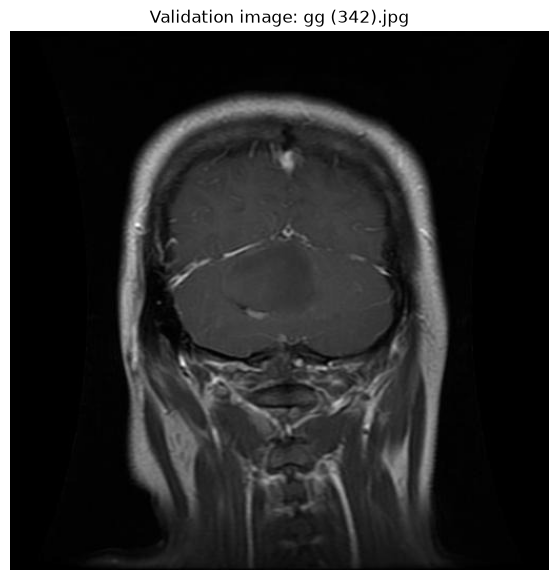

In [13]:
image_path = IMAGES_DIR / "val" / "gg (342).jpg"

image = cv2.imread(str(image_path))

if image is not None:
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(7, 7))
    plt.imshow(image)
    plt.title("Validation image: gg (342).jpg")
    plt.axis("off")
    plt.show()
else:
    print("Could not load the image.")

## 5. Review the Empty-Label Image

Inspect the displayed MRI image and determine whether it contains a visible tumor that should be annotated.

An empty YOLO label can represent an image with no target object, but it can also indicate a missing annotation.

We should not modify or delete the label until we understand the dataset's annotation rules.

## 6. Analyze Detection Class Distribution

Count the annotated objects belonging to each class across the training, validation, and test datasets.

Class IDs are defined in `data.yaml`:

- 0: Glioma
- 1: Meningioma
- 2: No Tumor
- 3: Pituitary

Each non-empty YOLO annotation line represents one annotated object.

This analysis helps identify class imbalance before model training. Empty label files are counted separately because they contain no annotated objects.

In [14]:
from collections import Counter

CLASS_NAMES = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}

for split in ["train", "val", "test"]:
    labels_dir = LABELS_DIR / split
    class_counts = Counter()

    for label_path in labels_dir.glob("*.txt"):
        for line in label_path.read_text().splitlines():
            parts = line.split()

            if len(parts) == 5:
                class_id = int(parts[0])
                class_counts[class_id] += 1

    print(f"\n{split.upper()}")

    for class_id, class_name in CLASS_NAMES.items():
        print(f"{class_name}: {class_counts[class_id]}")

    print("Total annotated objects:", sum(class_counts.values()))


TRAIN
Glioma: 1281
Meningioma: 1408
No Tumor: 676
Pituitary: 1687
Total annotated objects: 5052

VAL
Glioma: 153
Meningioma: 142
No Tumor: 98
Pituitary: 161
Total annotated objects: 554

TEST
Glioma: 68
Meningioma: 74
No Tumor: 35
Pituitary: 88
Total annotated objects: 265


## 7. Visualize YOLO Bounding Boxes

YOLO annotation files store each bounding box as:

`class_id x_center y_center width height`

The coordinates are normalized between 0 and 1.

To visualize a box, convert the normalized coordinates into pixel coordinates, then draw a rectangle on the image.

This step helps verify that the labels correspond to the correct regions in the MRI images.

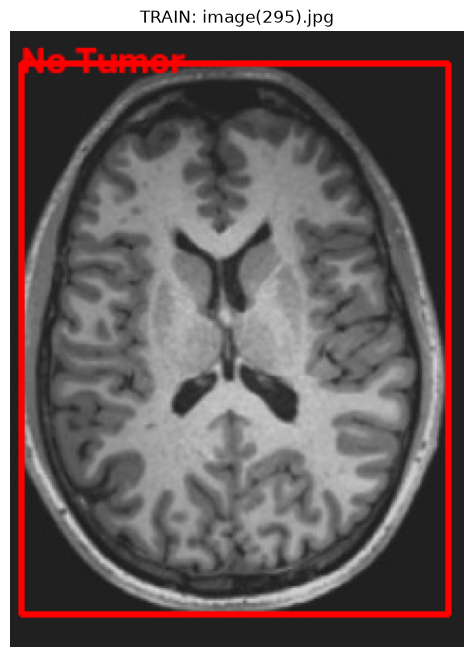

In [15]:
import random

split = "train"
images_dir = IMAGES_DIR / split
labels_dir = LABELS_DIR / split

label_paths = [
    p for p in labels_dir.glob("*.txt")
    if p.read_text().strip()
]

label_path = random.choice(label_paths)
image_path = next(
    p for p in images_dir.iterdir()
    if p.is_file()
    and p.stem == label_path.stem
    and p.suffix.lower() in IMAGE_EXTENSIONS
)

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

height, width = image.shape[:2]

for line in label_path.read_text().splitlines():
    parts = line.split()

    if len(parts) != 5:
        continue

    class_id = int(parts[0])
    x_center, y_center, box_width, box_height = map(float, parts[1:])

    x1 = int((x_center - box_width / 2) * width)
    y1 = int((y_center - box_height / 2) * height)
    x2 = int((x_center + box_width / 2) * width)
    y2 = int((y_center + box_height / 2) * height)

    cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

    class_name = CLASS_NAMES.get(class_id, str(class_id))
    cv2.putText(
        image,
        class_name,
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.title(f"{split.upper()}: {image_path.name}")
plt.axis("off")
plt.show()

## 8. Visualize Multiple YOLO Annotations

Display several randomly selected training images with their ground-truth bounding boxes and class labels.

This helps us inspect annotation quality across different images and identify obvious labeling errors before training YOLOv8.

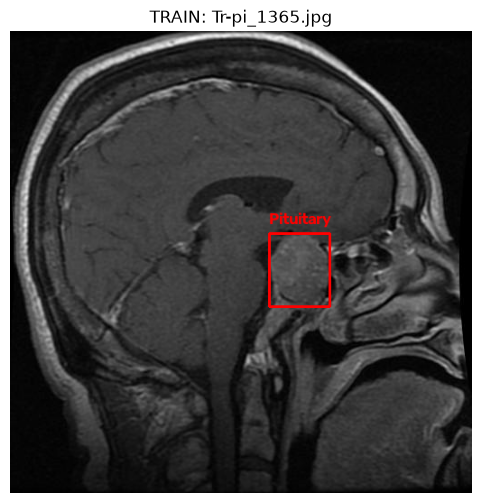

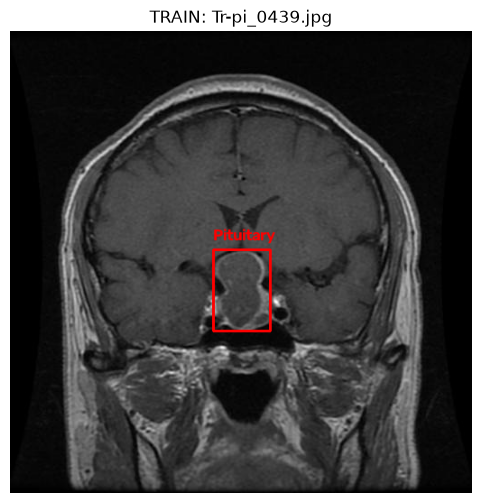

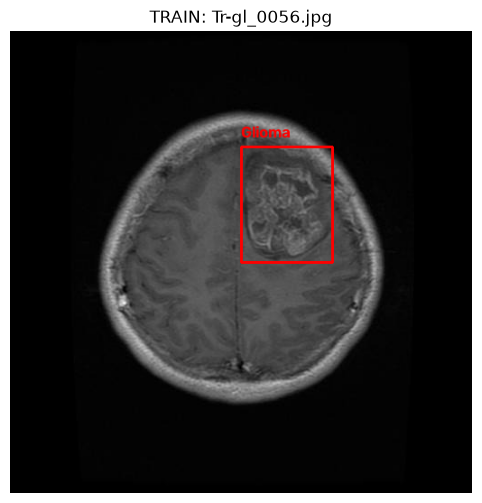

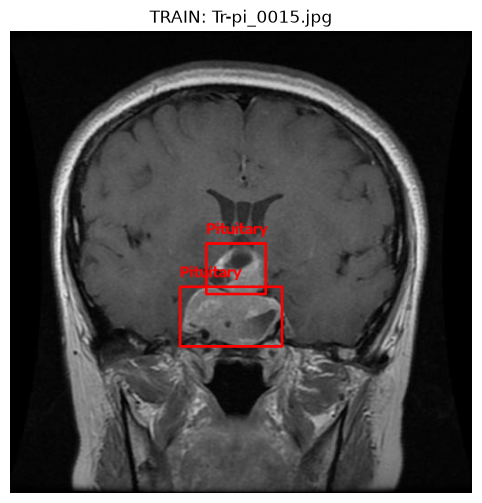

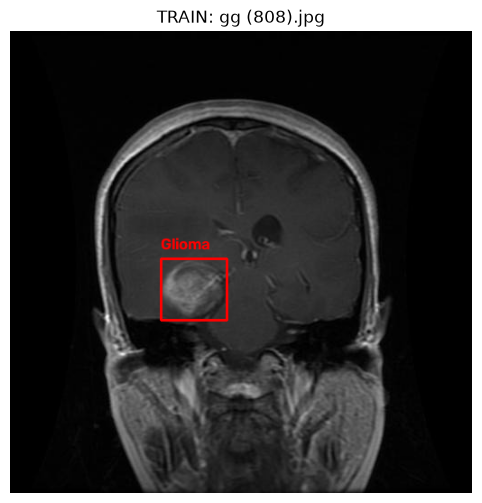

In [16]:
import random

split = "train"
images_dir = IMAGES_DIR / split
labels_dir = LABELS_DIR / split

label_paths = [
    p for p in labels_dir.glob("*.txt")
    if p.read_text().strip()
]

selected_labels = random.sample(
    label_paths,
    min(5, len(label_paths))
)

for label_path in selected_labels:
    image_path = next(
        p for p in images_dir.iterdir()
        if p.is_file()
        and p.stem == label_path.stem
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    for line in label_path.read_text().splitlines():
        parts = line.split()

        if len(parts) != 5:
            continue

        class_id = int(parts[0])
        x_center, y_center, box_width, box_height = map(
            float, parts[1:]
        )

        x1 = int((x_center - box_width / 2) * width)
        y1 = int((y_center - box_height / 2) * height)
        x2 = int((x_center + box_width / 2) * width)
        y2 = int((y_center + box_height / 2) * height)

        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

        class_name = CLASS_NAMES.get(class_id, str(class_id))
        cv2.putText(
            image,
            class_name,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(f"{split.upper()}: {image_path.name}")
    plt.axis("off")
    plt.show()

## 9. Inspect YOLO Annotation Examples

Read a few real label files to understand how classes and bounding boxes are represented.

This helps us verify whether the dataset uses the expected class IDs and annotation format.

In [18]:
# Display a few non-empty label files from the training set.

label_paths = [
    p for p in (LABELS_DIR / "train").glob("*.txt")
    if p.read_text().strip()
]

for label_path in label_paths[:5]:
    print(f"\nFile: {label_path.name}")
    print(label_path.read_text())



File: gg (103).txt
0 0.414062 0.490234 0.140625 0.132812


File: gg (104).txt
0 0.425781 0.486328 0.191406 0.164062


File: gg (105).txt
0 0.423828 0.477539 0.187500 0.173828


File: gg (106).txt
0 0.420898 0.463867 0.181641 0.150391


File: gg (107).txt
0 0.427734 0.458984 0.117188 0.128906



## 10. Inspect No Tumor Annotations

Find label files containing class ID 2 and inspect their annotations.

This helps us understand how the No Tumor class is represented in the detection dataset.

In [19]:
# Find label files containing class ID 2 (No Tumor).

no_tumor_labels = []

for label_path in (LABELS_DIR / "train").glob("*.txt"):
    for line in label_path.read_text().splitlines():
        parts = line.split()

        if len(parts) == 5 and parts[0] == "2":
            no_tumor_labels.append((label_path.name, line))
            break

print("Files containing No Tumor annotations:", len(no_tumor_labels))

for filename, annotation in no_tumor_labels[:5]:
    print(f"\nFile: {filename}")
    print(annotation)


Files containing No Tumor annotations: 676

File: 1.txt
2 0.502857 0.675714 0.851429 0.648571

File: 3.txt
2 0.512397 0.513051 0.770248 0.973899

File: 4.txt
2 0.525801 0.507601 0.809609 0.984797

File: 5.txt
2 0.497738 0.451357 0.737557 0.703620

File: 6.txt
2 0.499206 0.515079 0.671429 0.893651


## 11. Visualize No Tumor Annotations

Display three images labeled as No Tumor, with their ground-truth bounding boxes.

Compare the boxes with the image contents to understand what the dataset is annotating.

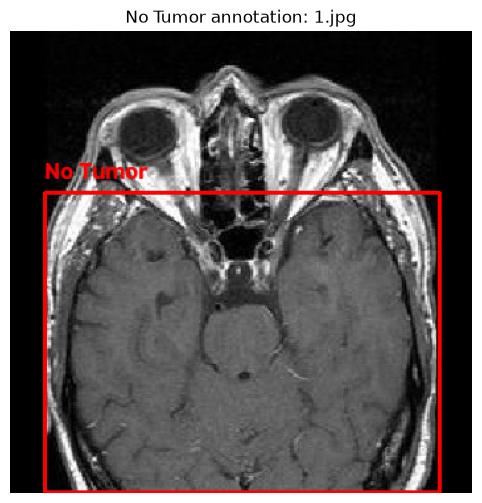

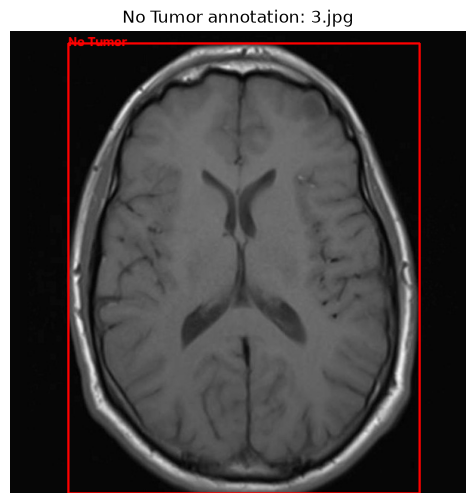

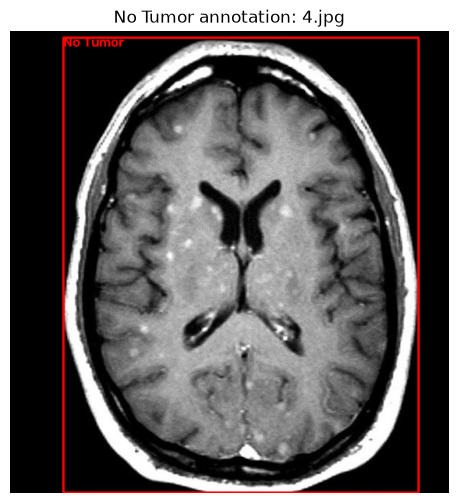

In [20]:
# Select three label files containing class ID 2.

selected_labels = no_tumor_labels[:3]

for filename, _ in selected_labels:
    label_path = LABELS_DIR / "train" / filename

    # Find the matching image.
    image_path = next(
        p for p in (IMAGES_DIR / "train").iterdir()
        if p.is_file()
        and p.stem == label_path.stem
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    # Read the image and convert BGR to RGB.
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    # Draw the bounding boxes from the label file.
    for line in label_path.read_text().splitlines():
        parts = line.split()

        if len(parts) != 5:
            continue

        class_id = int(parts[0])
        x_center, y_center, box_width, box_height = map(float, parts[1:])

        x1 = int((x_center - box_width / 2) * width)
        y1 = int((y_center - box_height / 2) * height)
        x2 = int((x_center + box_width / 2) * width)
        y2 = int((y_center + box_height / 2) * height)

        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)

        class_name = CLASS_NAMES.get(class_id, str(class_id))
        cv2.putText(
            image,
            class_name,
            (x1, max(y1 - 10, 20)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (255, 0, 0),
            2
        )

    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.title(f"No Tumor annotation: {image_path.name}")
    plt.axis("off")
    plt.show()

## 12. Check Bounding Box Boundaries

Verify that each bounding box stays inside the image boundaries.

A box is valid when its left, top, right, and bottom edges are all between 0 and 1.

In [21]:
for split in ["train", "val", "test"]:
    labels_dir = LABELS_DIR / split

    invalid_boxes = []

    for label_path in labels_dir.glob("*.txt"):
        for line_number, line in enumerate(
            label_path.read_text().splitlines(), start=1
        ):
            parts = line.split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])
            x_center, y_center, box_width, box_height = map(
                float, parts[1:]
            )

            x1 = x_center - box_width / 2
            y1 = y_center - box_height / 2
            x2 = x_center + box_width / 2
            y2 = y_center + box_height / 2

            if not (
                0 <= x1 <= 1
                and 0 <= y1 <= 1
                and 0 <= x2 <= 1
                and 0 <= y2 <= 1
            ):
                invalid_boxes.append(
                    (label_path.name, line_number, class_id,
                     round(x1, 3), round(y1, 3),
                     round(x2, 3), round(y2, 3))
                )

    print(f"\n{split.upper()}")
    print("Boxes outside image boundaries:", len(invalid_boxes))

    for box in invalid_boxes[:5]:
        print(box)


TRAIN
Boxes outside image boundaries: 12
('3.txt', 1, 2, 0.127, 0.026, 0.898, 1.0)
('image(110).txt', 1, 2, 0.004, 0.005, 1.0, 0.637)
('image(116).txt', 1, 2, 0.004, 0.005, 1.0, 0.856)
('image (11).txt', 1, 2, 0.004, 0.005, 1.0, 1.0)
('image(231).txt', 1, 2, 0.009, 0.007, 1.0, 0.97)

VAL
Boxes outside image boundaries: 3
('Tr-no_0058.txt', 1, 2, 0.004, 0.126, 1.0, 0.889)
('image(162).txt', 1, 2, 0.1, 0.279, 0.954, 1.0)
('image(319).txt', 1, 2, 0.01, 0.018, 1.0, 1.0)

TEST
Boxes outside image boundaries: 0


## 13. Inspect Exact Bounding Box Coordinates

Display the full-precision coordinates of the flagged boxes.

This helps distinguish genuinely invalid boxes from tiny floating-point differences near 0 or 1.

In [22]:
for split in ["train", "val", "test"]:
    labels_dir = LABELS_DIR / split
    print(f"\n{split.upper()}")

    checked = 0

    for label_path in labels_dir.glob("*.txt"):
        for line_number, line in enumerate(
            label_path.read_text().splitlines(), start=1
        ):
            parts = line.split()

            if len(parts) != 5:
                continue

            class_id = int(parts[0])
            x_center, y_center, box_width, box_height = map(
                float, parts[1:]
            )

            x1 = x_center - box_width / 2
            y1 = y_center - box_height / 2
            x2 = x_center + box_width / 2
            y2 = y_center + box_height / 2

            if not (
                0 <= x1 <= 1
                and 0 <= y1 <= 1
                and 0 <= x2 <= 1
                and 0 <= y2 <= 1
            ):
                print(f"\nFile: {label_path.name}")
                print(f"Line: {line_number}")
                print(f"Class ID: {class_id}")
                print(f"x1={x1:.12f}, y1={y1:.12f}")
                print(f"x2={x2:.12f}, y2={y2:.12f}")

                checked += 1

                if checked >= 5:
                    break

        if checked >= 5:
            break



TRAIN

File: 3.txt
Line: 1
Class ID: 2
x1=0.127273000000, y1=0.026101500000
x2=0.897521000000, y2=1.000000500000

File: image(110).txt
Line: 1
Class ID: 2
x1=0.004237500000, y1=0.005464000000
x2=1.000000500000, y2=0.636612000000

File: image(116).txt
Line: 1
Class ID: 2
x1=0.004255500000, y1=0.004630000000
x2=1.000000500000, y2=0.856482000000

File: image (11).txt
Line: 1
Class ID: 2
x1=0.003937500000, y1=0.005050500000
x2=1.000000500000, y2=0.999999500000

File: image(231).txt
Line: 1
Class ID: 2
x1=0.009063500000, y1=0.007389000000
x2=1.000000500000, y2=0.970443000000

VAL

File: Tr-no_0058.txt
Line: 1
Class ID: 2
x1=0.004237500000, y1=0.125925500000
x2=1.000000500000, y2=0.888888500000

File: image(162).txt
Line: 1
Class ID: 2
x1=0.099636500000, y1=0.279391500000
x2=0.954181500000, y2=1.000000500000

File: image(319).txt
Line: 1
Class ID: 2
x1=0.009615500000, y1=0.018404500000
x2=1.000000500000, y2=0.999999500000

TEST


## 14. Measure Bounding Box Boundary Violations

Measure how far bounding boxes extend outside the image boundaries.

This helps distinguish tiny numerical differences from significant annotation errors without modifying the dataset.

In [23]:
for split in ["train", "val", "test"]:
    labels_dir = LABELS_DIR / split
    violations = []

    for label_path in labels_dir.glob("*.txt"):
        for line_number, line in enumerate(
            label_path.read_text().splitlines(), start=1
        ):
            parts = line.split()

            if len(parts) != 5:
                continue

            x_center, y_center, box_width, box_height = map(
                float, parts[1:]
            )

            x1 = x_center - box_width / 2
            y1 = y_center - box_height / 2
            x2 = x_center + box_width / 2
            y2 = y_center + box_height / 2

            overflow = max(0, -x1, -y1, x2 - 1, y2 - 1)

            if overflow > 0:
                violations.append((label_path.name, overflow))

    print(f"\n{split.upper()}")
    print("Boxes outside boundaries:", len(violations))

    if violations:
        print(
            "Maximum overflow:",
            f"{max(item[1] for item in violations):.10f}"
        )


TRAIN
Boxes outside boundaries: 12
Maximum overflow: 0.0000005000

VAL
Boxes outside boundaries: 3
Maximum overflow: 0.0000005000

TEST
Boxes outside boundaries: 0


## 15. Investigate Empty Validation Labels

Identify images whose annotation files are empty.

An empty YOLO label file can represent an image with no target objects, so we should inspect it before deciding whether any correction is needed.

In [24]:
for split in ["train", "val", "test"]:
    labels_dir = LABELS_DIR / split
    empty_labels = [
        p for p in labels_dir.glob("*.txt")
        if not p.read_text().strip()
    ]

    print(f"\n{split.upper()}")
    print("Empty label files:", len(empty_labels))

    for label_path in empty_labels[:5]:
        print("Label:", label_path.name)

        matching_images = [
            p for p in (IMAGES_DIR / split).iterdir()
            if p.is_file()
            and p.stem == label_path.stem
            and p.suffix.lower() in IMAGE_EXTENSIONS
        ]

        for image_path in matching_images:
            print("Image:", image_path.name)


TRAIN
Empty label files: 0

VAL
Empty label files: 1
Label: gg (342).txt
Image: gg (342).jpg

TEST
Empty label files: 0


## 16. Verify YOLO Dataset Configuration

Check the existing `data.yaml` file and verify that its dataset path, split directories, number of classes, and class names are correct.

The dataset paths must match the environment where YOLOv8 training will run.

In [25]:
DATA_YAML_PATH = DETECTION_DIR / "data_local.yaml"

print("Configuration file:", DATA_YAML_PATH)
print("Configuration file exists:", DATA_YAML_PATH.exists())

if DATA_YAML_PATH.exists():
    with open(DATA_YAML_PATH, "r") as file:
        data_config = yaml.safe_load(file)

    print("\nCurrent configuration:")
    print(yaml.dump(data_config, sort_keys=False))

    dataset_root = Path(data_config["path"])
    print("Dataset path exists:", dataset_root.exists())

    for split in ["train", "val", "test"]:
        split_path = dataset_root / data_config[split]
        print(f"{split} path: {split_path}")
        print(f"Exists: {split_path.exists()}")

    print("\nNumber of classes:", data_config["nc"])
    print("Class names:", data_config["names"])


Configuration file: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/data_local.yaml
Configuration file exists: True

Current configuration:
path: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo
train: images/train
val: images/val
test: images/test
nc: 4
names:
  0: Glioma
  1: Meningioma
  2: No Tumor
  3: Pituitary

Dataset path exists: True
train path: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/train
Exists: True
val path: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/val
Exists: True
test path: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/test
Exists: True

Number of classes: 4
Class names: {0: 'Glioma', 1: 'Meningioma', 2: 'No Tumor', 3: 'Pituitary'}


## 17. Create a Local YOLO Dataset Configuration

Create a separate `data_local.yaml` file for training YOLOv8 from the local Jupyter environment.

Keep the existing `data.yaml` unchanged because it uses the Docker container path.

The configuration defines the dataset location, train/validation/test folders, and class names.

In [26]:
LOCAL_DATA_YAML_PATH = DETECTION_DIR / "data_local.yaml"

local_config = {
    "path": str(DETECTION_DIR.resolve()),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 4,
    "names": {
        0: "Glioma",
        1: "Meningioma",
        2: "No Tumor",
        3: "Pituitary",
    },
}

with open(LOCAL_DATA_YAML_PATH, "w") as file:
    yaml.safe_dump(local_config, file, sort_keys=False)

DATA_YAML_PATH = LOCAL_DATA_YAML_PATH
print("Created:", LOCAL_DATA_YAML_PATH)
print("\nConfiguration:")
print(LOCAL_DATA_YAML_PATH.read_text())


Created: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/data_local.yaml

Configuration:
path: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo
train: images/train
val: images/val
test: images/test
nc: 4
names:
  0: Glioma
  1: Meningioma
  2: No Tumor
  3: Pituitary



In [27]:
LOCAL_DATA_YAML_PATH = DETECTION_DIR / "data_local.yaml"
DATA_YAML_PATH = LOCAL_DATA_YAML_PATH
print("Using local dataset configuration:", DATA_YAML_PATH)


Using local dataset configuration: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/data_local.yaml


### Verify the Local Dataset Configuration

Check that the dataset root and all three image directories exist before starting training.

In [28]:
with open(LOCAL_DATA_YAML_PATH, "r") as file:
    config = yaml.safe_load(file)

dataset_root = Path(config["path"])

for split in ["train", "val", "test"]:
    image_dir = dataset_root / config[split]
    label_dir = dataset_root / "labels" / split

    print(f"\n{split.upper()}")
    print("Images directory exists:", image_dir.is_dir())
    print("Labels directory exists:", label_dir.is_dir())

print("\nNumber of classes:", config["nc"])
print("Class names:", config["names"])


TRAIN
Images directory exists: True
Labels directory exists: True

VAL
Images directory exists: True
Labels directory exists: True

TEST
Images directory exists: True
Labels directory exists: True

Number of classes: 4
Class names: {0: 'Glioma', 1: 'Meningioma', 2: 'No Tumor', 3: 'Pituitary'}


## 18. Check YOLOv8 Installation

Verify that the Ultralytics package is installed and check its version before training.

Using the notebook's Python environment helps avoid package and kernel mismatches.

In [29]:
try:
    import ultralytics
    print("Ultralytics version:", ultralytics.__version__)
except ImportError as exc:
    raise ImportError(
        "Ultralytics is required. Install project dependencies before running this notebook."
    ) from exc


Ultralytics version: 8.4.183


In [30]:
import sys
import importlib.metadata as metadata

print("Python executable:", sys.executable)

try:
    print("Ultralytics version:", metadata.version("ultralytics"))

    from ultralytics import YOLO

    print("YOLOv8 import: successful")

except metadata.PackageNotFoundError:
    print("Ultralytics is not installed in this notebook environment.")

except ImportError as error:
    print("Import error:", error)

Python executable: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/.venv/bin/python
Ultralytics version: 8.4.183
YOLOv8 import: successful


## 20. Check Google Colab GPU

Check whether Google Colab has assigned a GPU and inspect the available PyTorch and CUDA versions before training YOLOv8.

In [31]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        f"{torch.cuda.get_device_properties(0).total_memory / (1024 ** 3):.2f} GB"
    )
else:
    print("No GPU detected. Check Runtime > Change runtime type.")

PyTorch version: 2.14.1+cu130
CUDA available: False
No GPU detected. Check Runtime > Change runtime type.



## 1. Validate YOLO Annotations

YOLO uses a text file for each annotated image.

Each line represents one bounding box and contains:
- `class_id`: object class, from 0 to 3.
- `x_center`: horizontal center of the box.
- `y_center`: vertical center of the box.
- `width`: box width.
- `height`: box height.

Coordinates are normalized between 0 and 1.

We will check that:
- Every image has a corresponding label file.
- Each label contains five valid values per bounding box.
- Class IDs are between 0 and 3.
- Coordinates are within the valid range.


In [32]:

from pathlib import Path

CLASS_NAMES = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def validate_split(split):
    images_dir = IMAGES_DIR / split
    labels_dir = LABELS_DIR / split

    images = [
        p for p in images_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    image_stems = {p.stem for p in images}
    label_files = {
        p.stem: p for p in labels_dir.glob("*.txt")
    }

    missing_labels = image_stems - label_files.keys()
    orphan_labels = label_files.keys() - image_stems

    invalid_lines = []
    empty_labels = []
    class_counts = {class_id: 0 for class_id in CLASS_NAMES}

    for stem in image_stems & label_files.keys():
        label_path = label_files[stem]
        content = label_path.read_text().strip()

        if not content:
            empty_labels.append(stem)
            continue

        for line_number, line in enumerate(content.splitlines(), start=1):
            parts = line.split()

            if len(parts) != 5:
                invalid_lines.append(
                    (label_path.name, line_number, "Expected 5 values")
                )
                continue

            try:
                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])
            except ValueError:
                invalid_lines.append(
                    (label_path.name, line_number, "Non-numeric value")
                )
                continue

            if class_id not in CLASS_NAMES:
                invalid_lines.append(
                    (label_path.name, line_number, "Invalid class ID")
                )
                continue

            if not all(0 <= value <= 1 for value in (x, y, w, h)):
                invalid_lines.append(
                    (label_path.name, line_number, "Coordinates outside 0-1")
                )
                continue

            if w == 0 or h == 0:
                invalid_lines.append(
                    (label_path.name, line_number, "Zero-width or height box")
                )
                continue

            class_counts[class_id] += 1

    print(f"\n--- {split.upper()} ---")
    print(f"Images: {len(images)}")
    print(f"Label files: {len(label_files)}")
    print(f"Images missing labels: {len(missing_labels)}")
    print(f"Labels without images: {len(orphan_labels)}")
    print(f"Empty label files: {len(empty_labels)}")
    print(f"Invalid annotation lines: {len(invalid_lines)}")
    print("\nBounding boxes by class:")

    for class_id, count in class_counts.items():
        print(f"  {CLASS_NAMES[class_id]}: {count}")

    if invalid_lines:
        print("\nFirst 5 invalid lines:")
        for item in invalid_lines[:5]:
            print(item)

for split in ["train", "val", "test"]:
    validate_split(split)



--- TRAIN ---
Images: 4501
Label files: 4501
Images missing labels: 0
Labels without images: 0
Empty label files: 0
Invalid annotation lines: 0

Bounding boxes by class:
  Glioma: 1281
  Meningioma: 1408
  No Tumor: 676
  Pituitary: 1687

--- VAL ---
Images: 510
Label files: 510
Images missing labels: 0
Labels without images: 0
Empty label files: 1
Invalid annotation lines: 0

Bounding boxes by class:
  Glioma: 153
  Meningioma: 142
  No Tumor: 98
  Pituitary: 161

--- TEST ---
Images: 236
Label files: 236
Images missing labels: 0
Labels without images: 0
Empty label files: 0
Invalid annotation lines: 0

Bounding boxes by class:
  Glioma: 68
  Meningioma: 74
  No Tumor: 35
  Pituitary: 88


## 21. Locate the Detection Dataset

Find the `detection_yolo` directory inside the current Colab environment.

Verify that it contains the images and labels folders for train, validation, and test.

In [33]:
from pathlib import Path

print("Detection dataset:", DETECTION_DIR)
print("Images:", IMAGES_DIR)
print("Labels:", LABELS_DIR)
print("Project contents:")
for path in sorted(PROJECT_ROOT.iterdir()):
    print(path)


Detection dataset: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo
Images: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images
Labels: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/labels
Project contents:
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/.dockerignore
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/.env.example
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/.git
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/.gitignore
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/.venv
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/.venv~deactivate
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/Dockerfile
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/README.md
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/airflow
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/api
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/app
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/artifacts
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/compose.yaml
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/dags
/home/lahcen404/

## 22. Verify Dataset Structure in Google Colab

Check that the detection dataset contains the expected image and annotation folders for train, validation, and test.

Confirm that the number of images and labels matches the results from our earlier validation.

In [34]:
from pathlib import Path

DETECTION_DIR = PROJECT_ROOT / "datasets" / "detection_yolo"
IMAGES_DIR = DETECTION_DIR / "images"
LABELS_DIR = DETECTION_DIR / "labels"

for split in ["train", "val", "test"]:
    image_dir = IMAGES_DIR / split
    label_dir = LABELS_DIR / split

    images = [
        p for p in image_dir.iterdir()
        if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]

    labels = list(label_dir.glob("*.txt"))

    print(f"\n--- {split.upper()} ---")
    print("Image directory exists:", image_dir.is_dir())
    print("Label directory exists:", label_dir.is_dir())
    print("Images:", len(images))
    print("Labels:", len(labels))
    print("Counts match:", len(images) == len(labels))


--- TRAIN ---
Image directory exists: True
Label directory exists: True
Images: 4501
Labels: 4501
Counts match: True

--- VAL ---
Image directory exists: True
Label directory exists: True
Images: 510
Labels: 510
Counts match: True

--- TEST ---
Image directory exists: True
Label directory exists: True
Images: 236
Labels: 236
Counts match: True


## 23. Create the YOLO Dataset Configuration

Create the local YOLO dataset configuration using the repository dataset path.

The file defines the training, validation, and test image directories, along with the four class IDs and names.

In [35]:
import yaml
from pathlib import Path

DETECTION_DIR = DETECTION_DIR

data_config = {
    "path": str(DETECTION_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 4,
    "names": {
        0: "Glioma",
        1: "Meningioma",
        2: "No Tumor",
        3: "Pituitary",
    },
}

DATA_YAML_PATH = DETECTION_DIR / "data_local.yaml"

with open(DATA_YAML_PATH, "w") as file:
    yaml.safe_dump(data_config, file, sort_keys=False)

print(DATA_YAML_PATH.read_text())

path: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo
train: images/train
val: images/val
test: images/test
nc: 4
names:
  0: Glioma
  1: Meningioma
  2: No Tumor
  3: Pituitary



## 24. Check GPU Availability

Check whether Google Colab has assigned a GPU and whether PyTorch can use CUDA.

GPU availability determines the device and batch size we should use for YOLOv8 training.

In [36]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        f"GPU memory: "
        f"{torch.cuda.get_device_properties(0).total_memory / (1024 ** 3):.2f} GB"
    )
else:
    print("No GPU detected. Select Runtime > Change runtime type > GPU.")

PyTorch version: 2.14.1+cu130
CUDA available: False
No GPU detected. Select Runtime > Change runtime type > GPU.


## 28. Load the Pretrained YOLOv8n Model

Load the pretrained YOLOv8 nano detection model. We will fine-tune it on our four brain MRI classes using the local Colab dataset configuration.

In [37]:
model = YOLO("yolov8n.pt")

print("Model loaded successfully.")
print("Dataset configuration:", DATA_YAML_PATH)

Model loaded successfully.
Dataset configuration: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/data_local.yaml


## 29. Configure YOLOv8 Training

Define the training hyperparameters and data augmentation settings.

We use pretrained YOLOv8n weights and a GPU-compatible configuration. Training performance will be monitored on the validation split.

In [38]:
TRAINING_CONFIG = {
    "data": str(DATA_YAML_PATH),
    "epochs": 30,
    "imgsz": 640,
    "batch": 16,
    "device": DEVICE,
    "patience": 8,
    "workers": 2,
    "optimizer": "auto",
    "project": str(RUNS_DIR),
    "name": "brainscan_yolov8n",
    "exist_ok": True,
    "plots": True,
    "save": True,
    "seed": 42,
    "deterministic": True,

    # Data augmentation
    "hsv_h": 0.015,
    "hsv_s": 0.5,
    "hsv_v": 0.3,
    "degrees": 5.0,
    "translate": 0.1,
    "scale": 0.3,
    "fliplr": 0.5,
    "flipud": 0.0,
    "mosaic": 0.5,
    "mixup": 0.0,
}

print("Training configuration:")
for key, value in TRAINING_CONFIG.items():
    print(f"{key}: {value}")

Training configuration:
data: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/data_local.yaml
epochs: 30
imgsz: 640
batch: 16
device: cpu
patience: 8
workers: 2
optimizer: auto
project: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/runs/detect
name: brainscan_yolov8n
exist_ok: True
plots: True
save: True
seed: 42
deterministic: True
hsv_h: 0.015
hsv_s: 0.5
hsv_v: 0.3
degrees: 5.0
translate: 0.1
scale: 0.3
fliplr: 0.5
flipud: 0.0
mosaic: 0.5
mixup: 0.0


## 30. Validate Dataset with YOLOv8

Run YOLOv8's dataset checks to verify that the configuration can be loaded and that the images and annotations are readable.

Resolve any dataset errors before starting training.

In [39]:
from ultralytics.data.utils import check_det_dataset

checked_data = check_det_dataset(str(DATA_YAML_PATH))

print("Dataset validation completed.")
print("Train path:", checked_data["train"])
print("Validation path:", checked_data["val"])
print("Number of classes:", checked_data["nc"])
print("Class names:", checked_data["names"])

Dataset validation completed.
Train path: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/train
Validation path: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/val
Number of classes: 4
Class names: {0: 'Glioma', 1: 'Meningioma', 2: 'No Tumor', 3: 'Pituitary'}



## 31. Train YOLOv8n

Train the pretrained YOLOv8 Nano model on the BrainScanAI-V2 detection dataset.

- **Pretrained weights:** Start from a model that has already learned general image features.
- **Training:** Learn to detect and locate the four classes in our brain MRI dataset.
- **Validation:** Evaluate performance on validation images during training.
- **Best weights:** Save the model checkpoint with the best validation performance.


In [ ]:
from ultralytics import YOLO

# loaaad pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

results = model.train(**TRAINING_CONFIG)


## 32. Inspect YOLOv8 Training Results

Read the training metrics saved by Ultralytics and inspect the best-model checkpoint path.


In [40]:

from pathlib import Path
import pandas as pd

RUN_DIR = RUNS_DIR / "brainscan_yolov8n"

# Read metrics recorded during training when the local run directory exists.
metrics_path = RUN_DIR / "results.csv"
if metrics_path.exists():
    metrics_df = pd.read_csv(metrics_path)
    metrics_df.columns = metrics_df.columns.str.strip()
    print("Last training epochs:")
    display(metrics_df.tail())
else:
    print("No local training metrics found; use the imported best.pt checkpoint.")

# Check that the model checkpoints exist
for filename in ["best.pt", "last.pt"]:
    checkpoint = RUN_DIR / "weights" / filename
    print(f"{filename}: {'Found' if checkpoint.exists() else 'Not found'}")


No local training metrics found; use the imported best.pt checkpoint.
best.pt: Not found
last.pt: Not found



## 33. Evaluate YOLOv8 on the Test Set

Load the best trained checkpoint and evaluate it on the test split.

The test set is used for final evaluation, not for adjusting training parameters.


In [41]:

from ultralytics import YOLO
from pathlib import Path

BEST_MODEL_PATH = MODELS_DIR / "best.pt"
if not BEST_MODEL_PATH.exists():
    BEST_MODEL_PATH = RUN_DIR / "weights" / "best.pt"

# Load the best trained model
best_model = YOLO(str(BEST_MODEL_PATH))

# Evaluate on the test split
test_results = best_model.val(
    data=str(DATA_YAML_PATH),
    split="test",
    imgsz=640,
    batch=16,
    device=DEVICE,
    plots=True,
)

print("Test evaluation completed.")


Ultralytics 8.4.183 🚀 Python-3.12.15 torch-2.14.1+cu130 CPU (11th Gen Intel Core i5-1135G7 @ 2.40GHz)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 56.7±51.7 MB/s, size: 36.4 KB)
val: Scanning /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/labels/test.cache... 236 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 236/236 55.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 1.4s/it 20.4s1.3s
                   all        236        265      0.926      0.927      0.955      0.719
                Glioma         57         68      0.849      0.826      0.887      0.609
            Meningioma         72         74      0.943      0.973      0.981      0.746
              No Tumor         35         35      0.988          1      0.995      0.798
             Pituitary         82         88      0.924      0.909   


## 34. Inspect Test Evaluation Outputs

List the plots and files generated during test evaluation so we can examine the confusion matrix and prediction results.


In [42]:
from pathlib import Path

validation_dirs = sorted(
    (path for path in RUNS_DIR.glob("val*") if path.is_dir()),
    key=lambda path: path.stat().st_mtime,
    reverse=True,
)
TEST_RUN_DIR = validation_dirs[0] if validation_dirs else None

if TEST_RUN_DIR is None:
    print("No YOLO validation output directory was found.")
else:
    print("Using validation output:", TEST_RUN_DIR)
    for path in sorted(TEST_RUN_DIR.iterdir()):
        print(path.name)


Using validation output: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/runs/detect/val-3
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg



## 35. Inspect the Test Confusion Matrix

Display the confusion matrix generated during test evaluation to understand which classes the model confuses with one another.


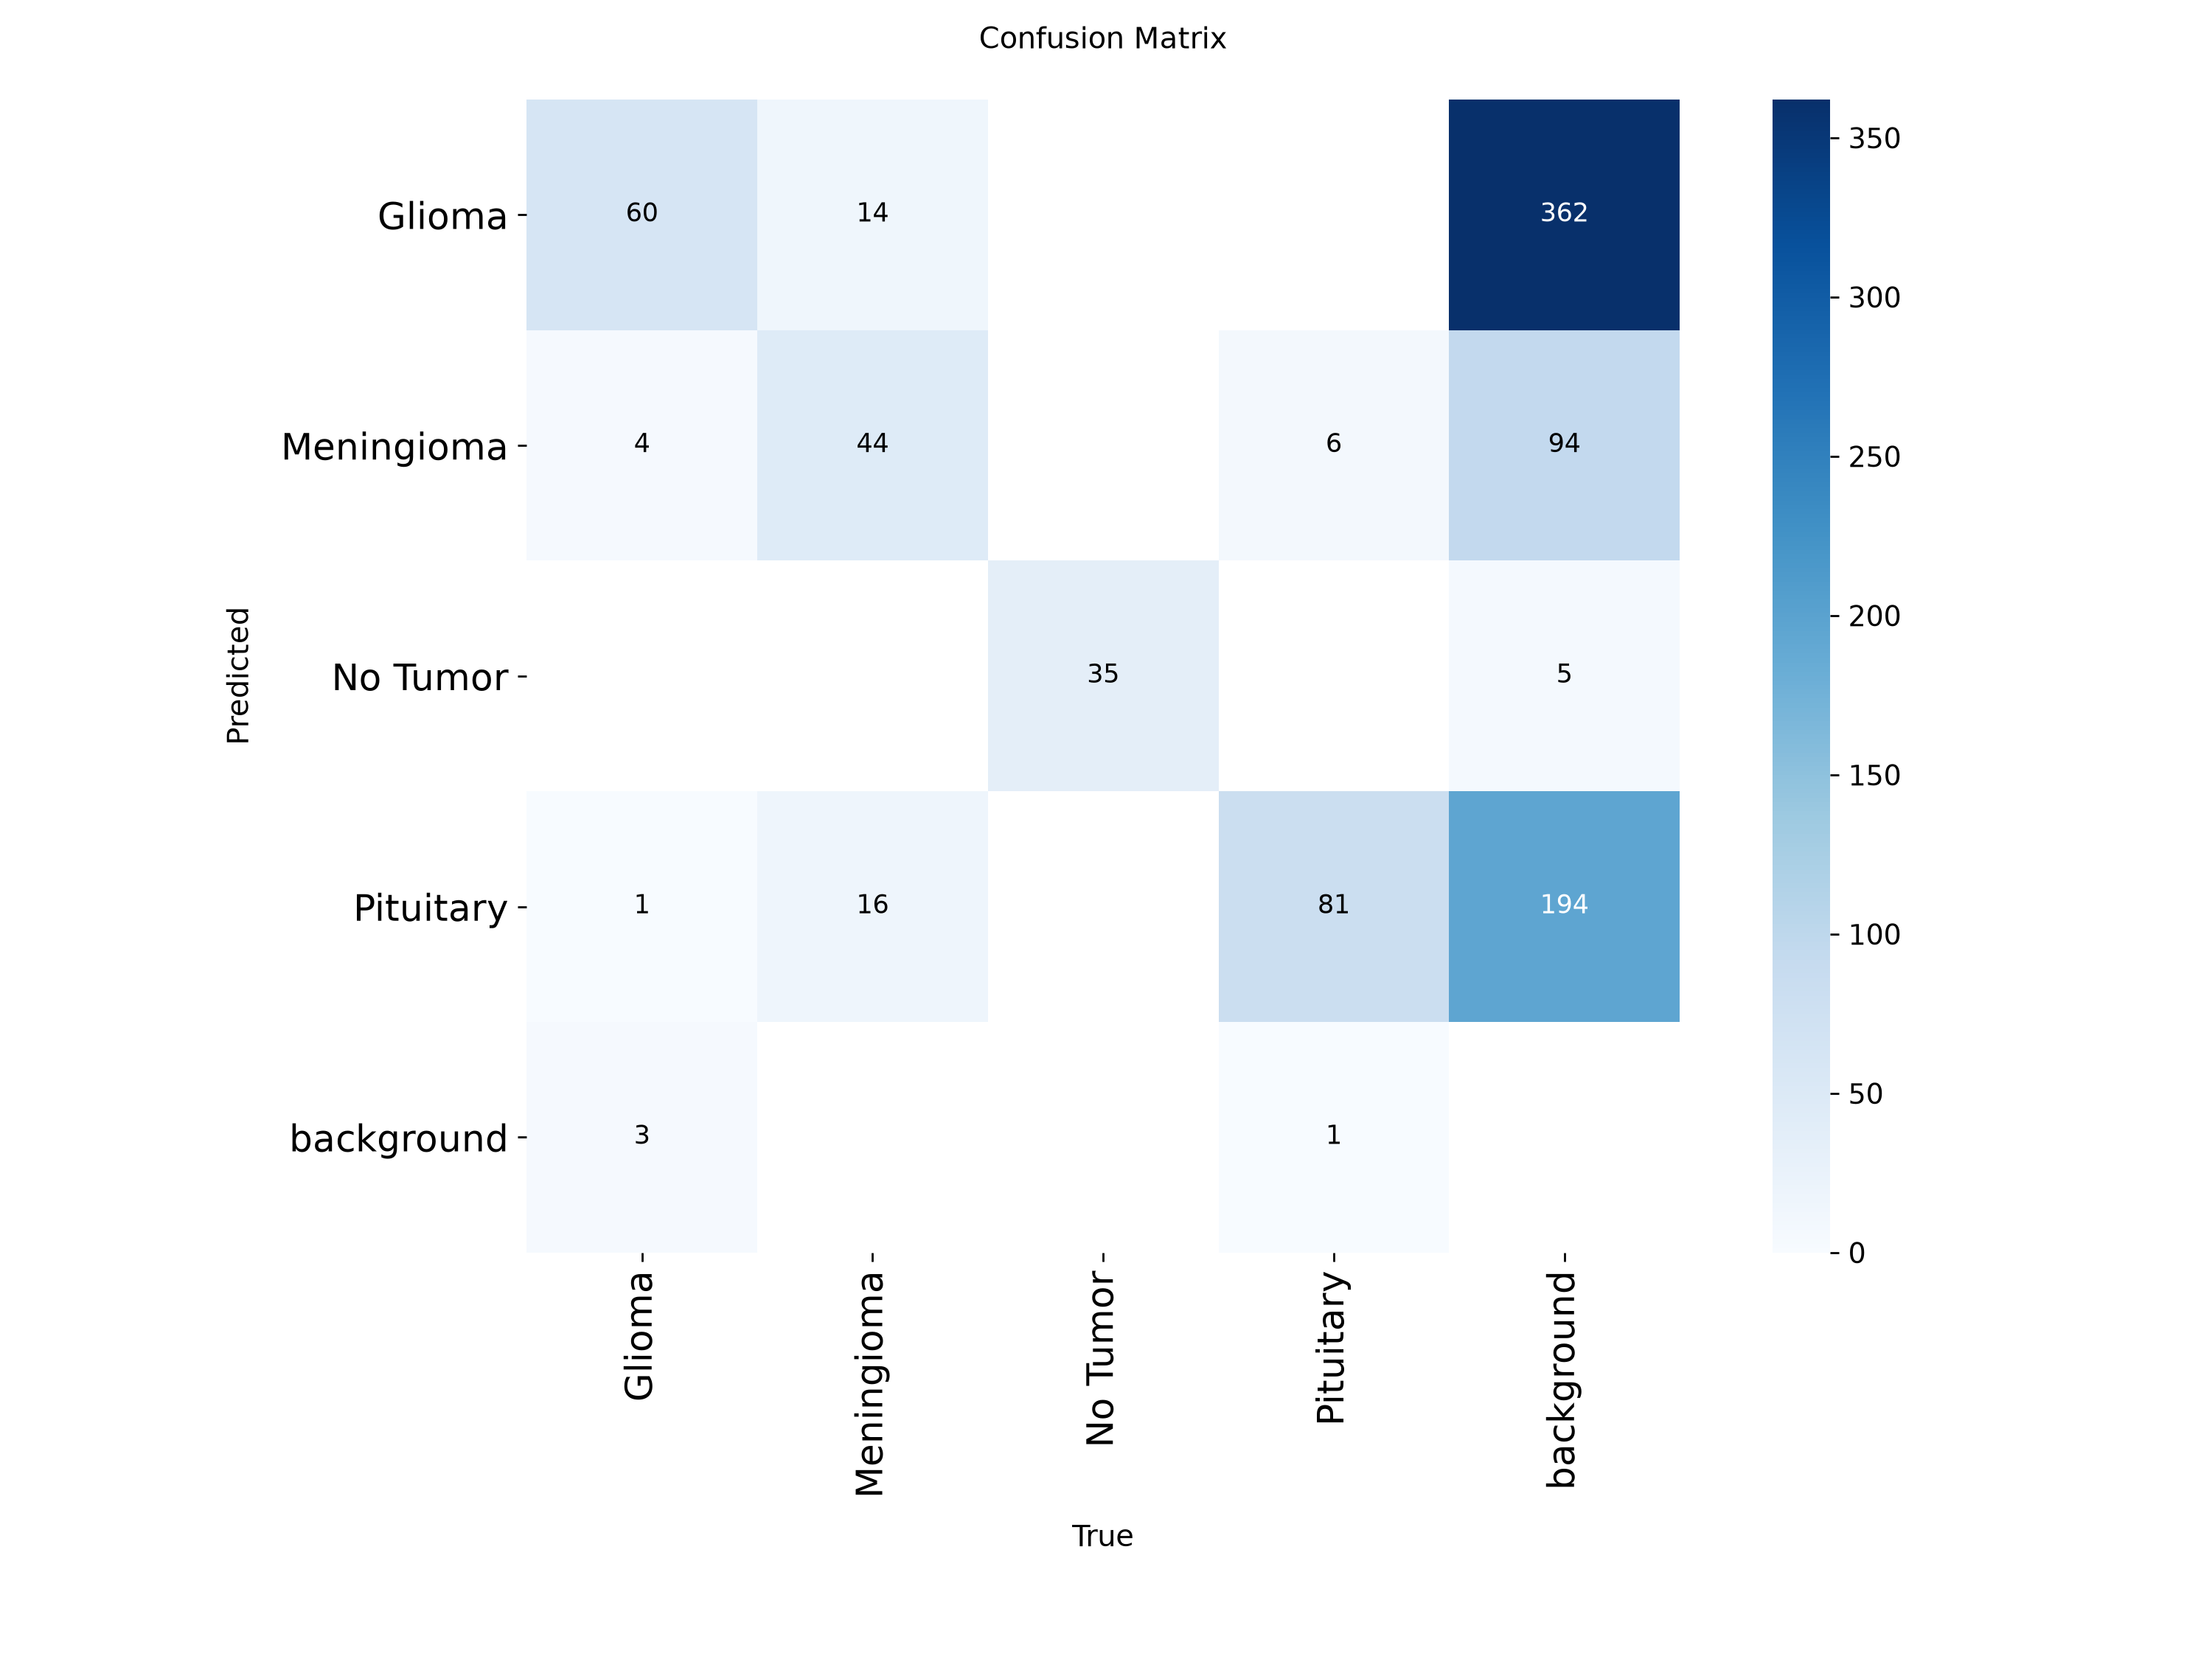

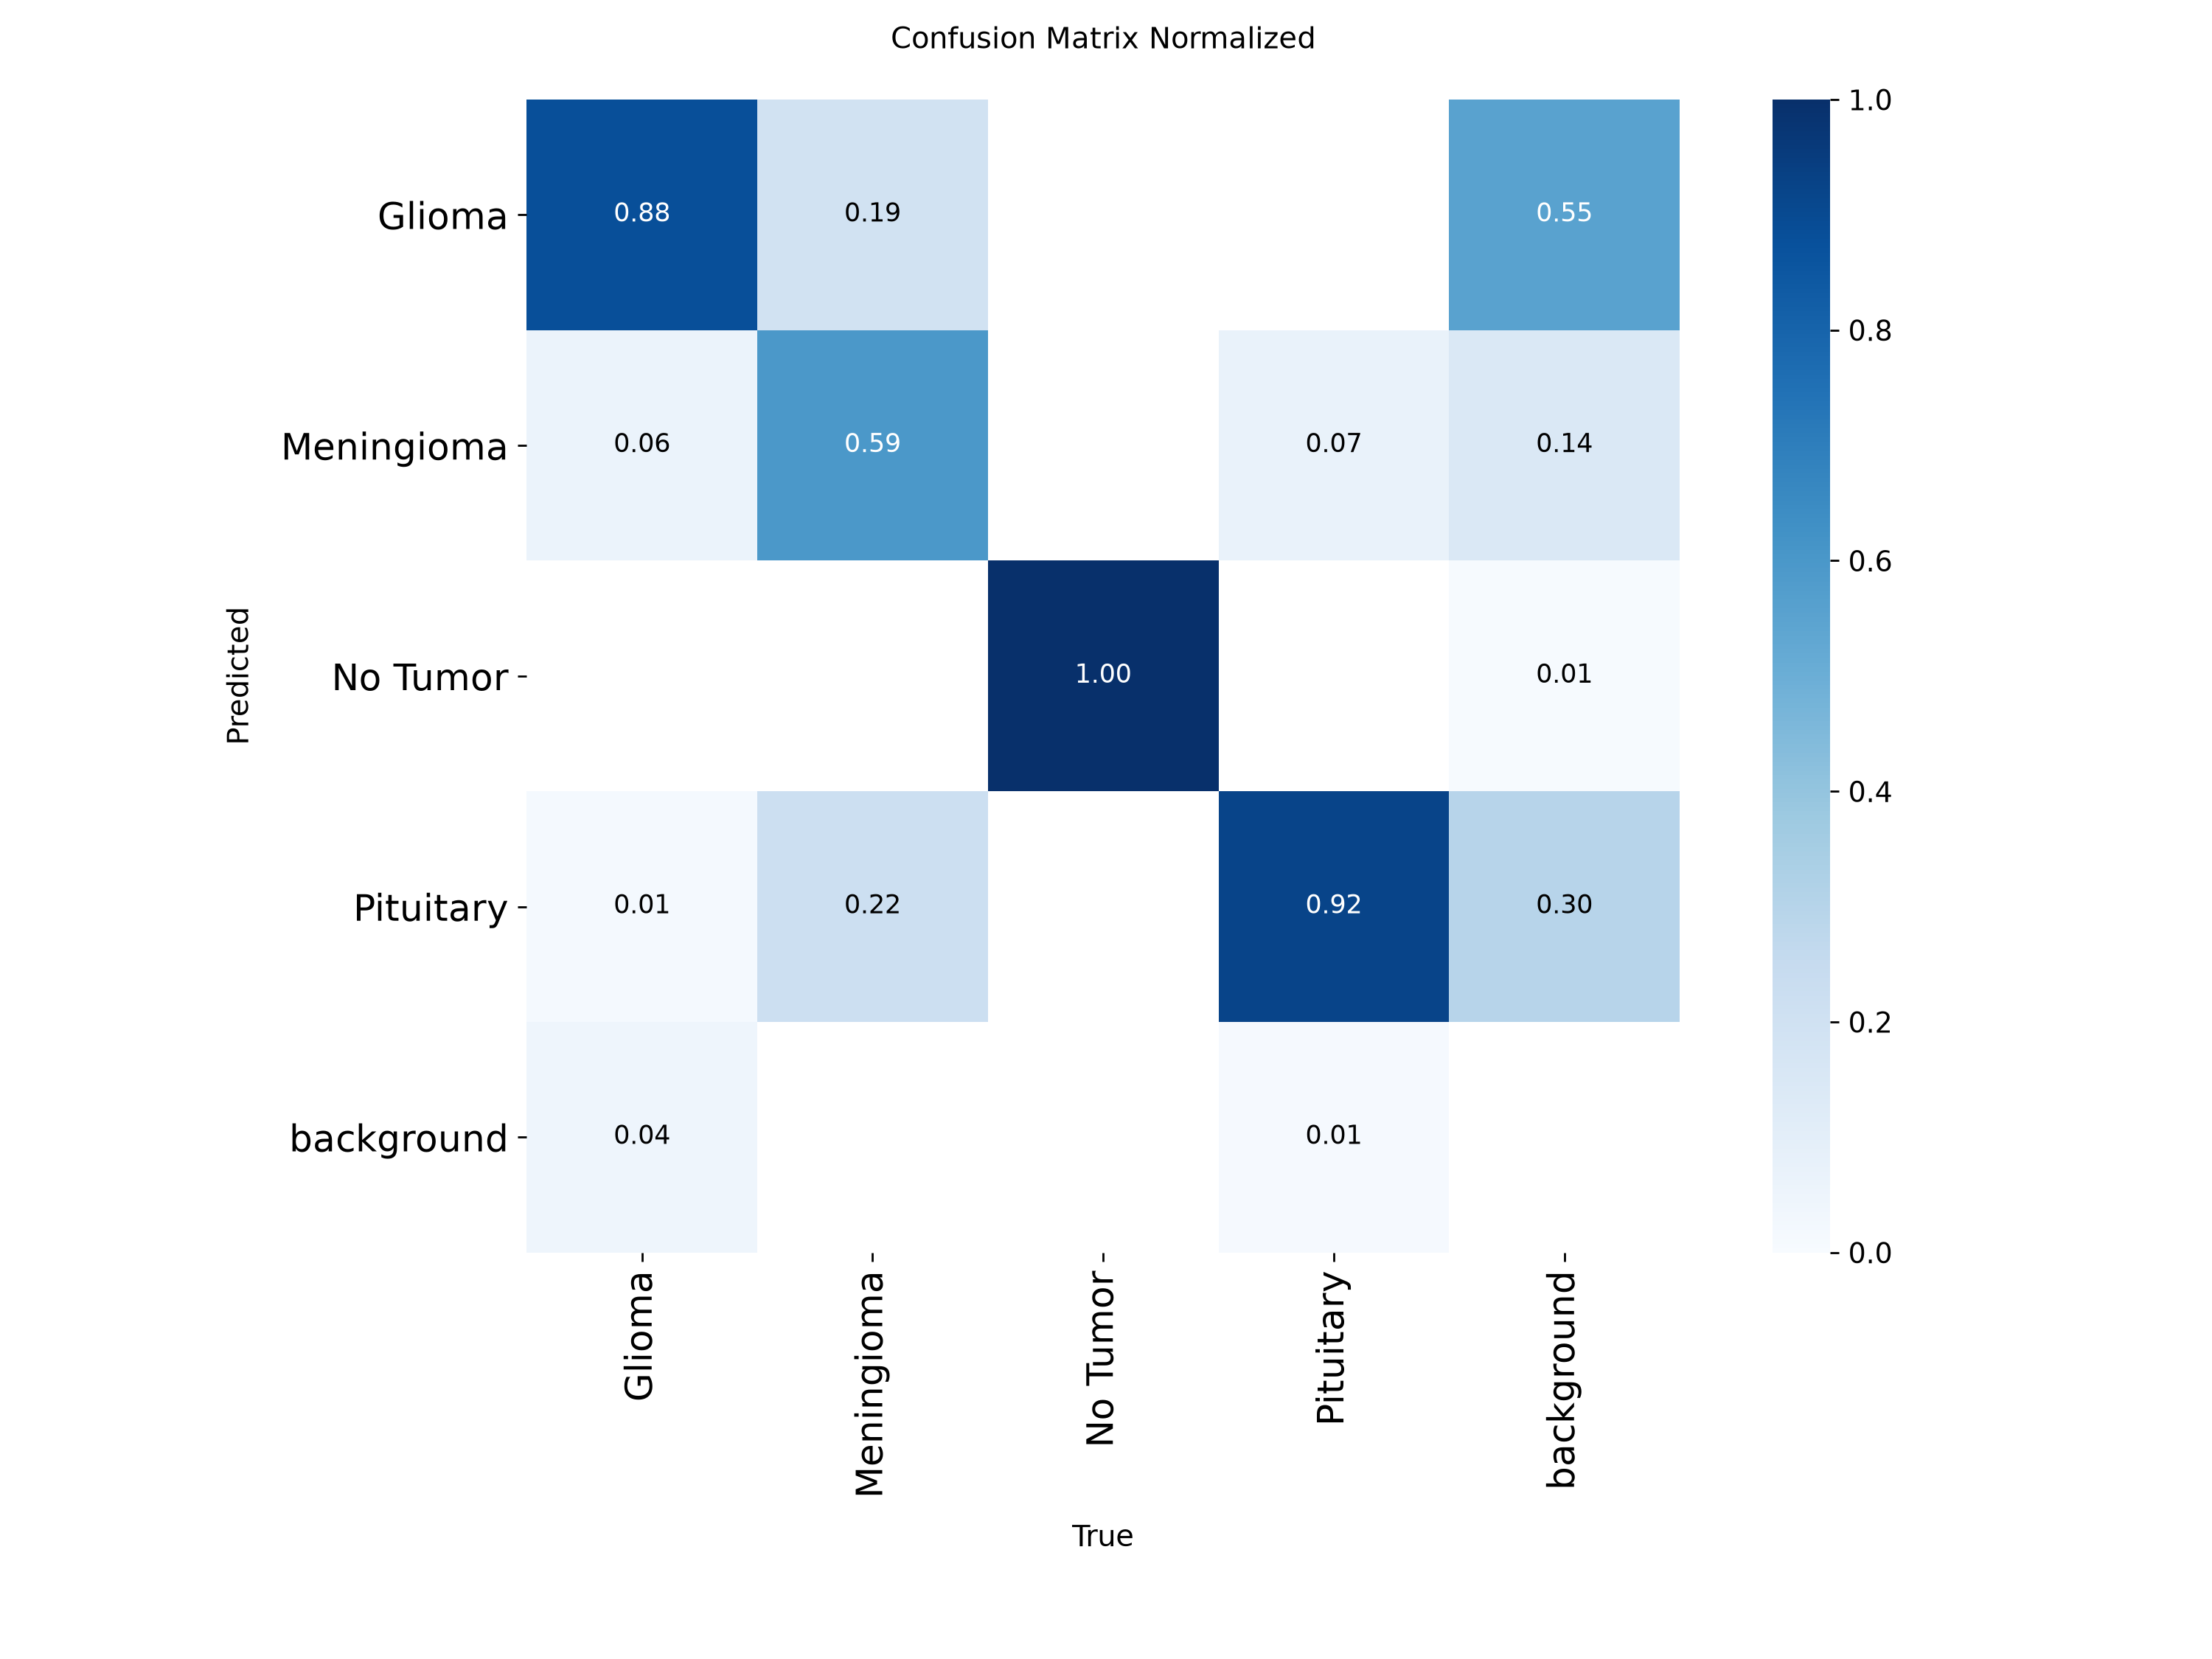

In [43]:
from IPython.display import display, Image

if "TEST_RUN_DIR" not in globals() or TEST_RUN_DIR is None:
    validation_dirs = sorted(
        (path for path in RUNS_DIR.glob("val*") if path.is_dir()),
        key=lambda path: path.stat().st_mtime,
        reverse=True,
    )
    TEST_RUN_DIR = validation_dirs[0] if validation_dirs else None

if TEST_RUN_DIR is None:
    print("No YOLO validation plots were found. Run the evaluation cell first.")
else:
    for filename in ("confusion_matrix.png", "confusion_matrix_normalized.png"):
        plot_path = TEST_RUN_DIR / filename
        if plot_path.exists():
            display(Image(filename=str(plot_path)))
        else:
            print("Plot not found:", plot_path)


## 36. Compare Ground-Truth and Predicted Bounding Boxes

Display the test images with their real annotations and the bounding boxes predicted by YOLOv8. Compare the box locations and class labels to identify missed detections, false positives, and localization errors.

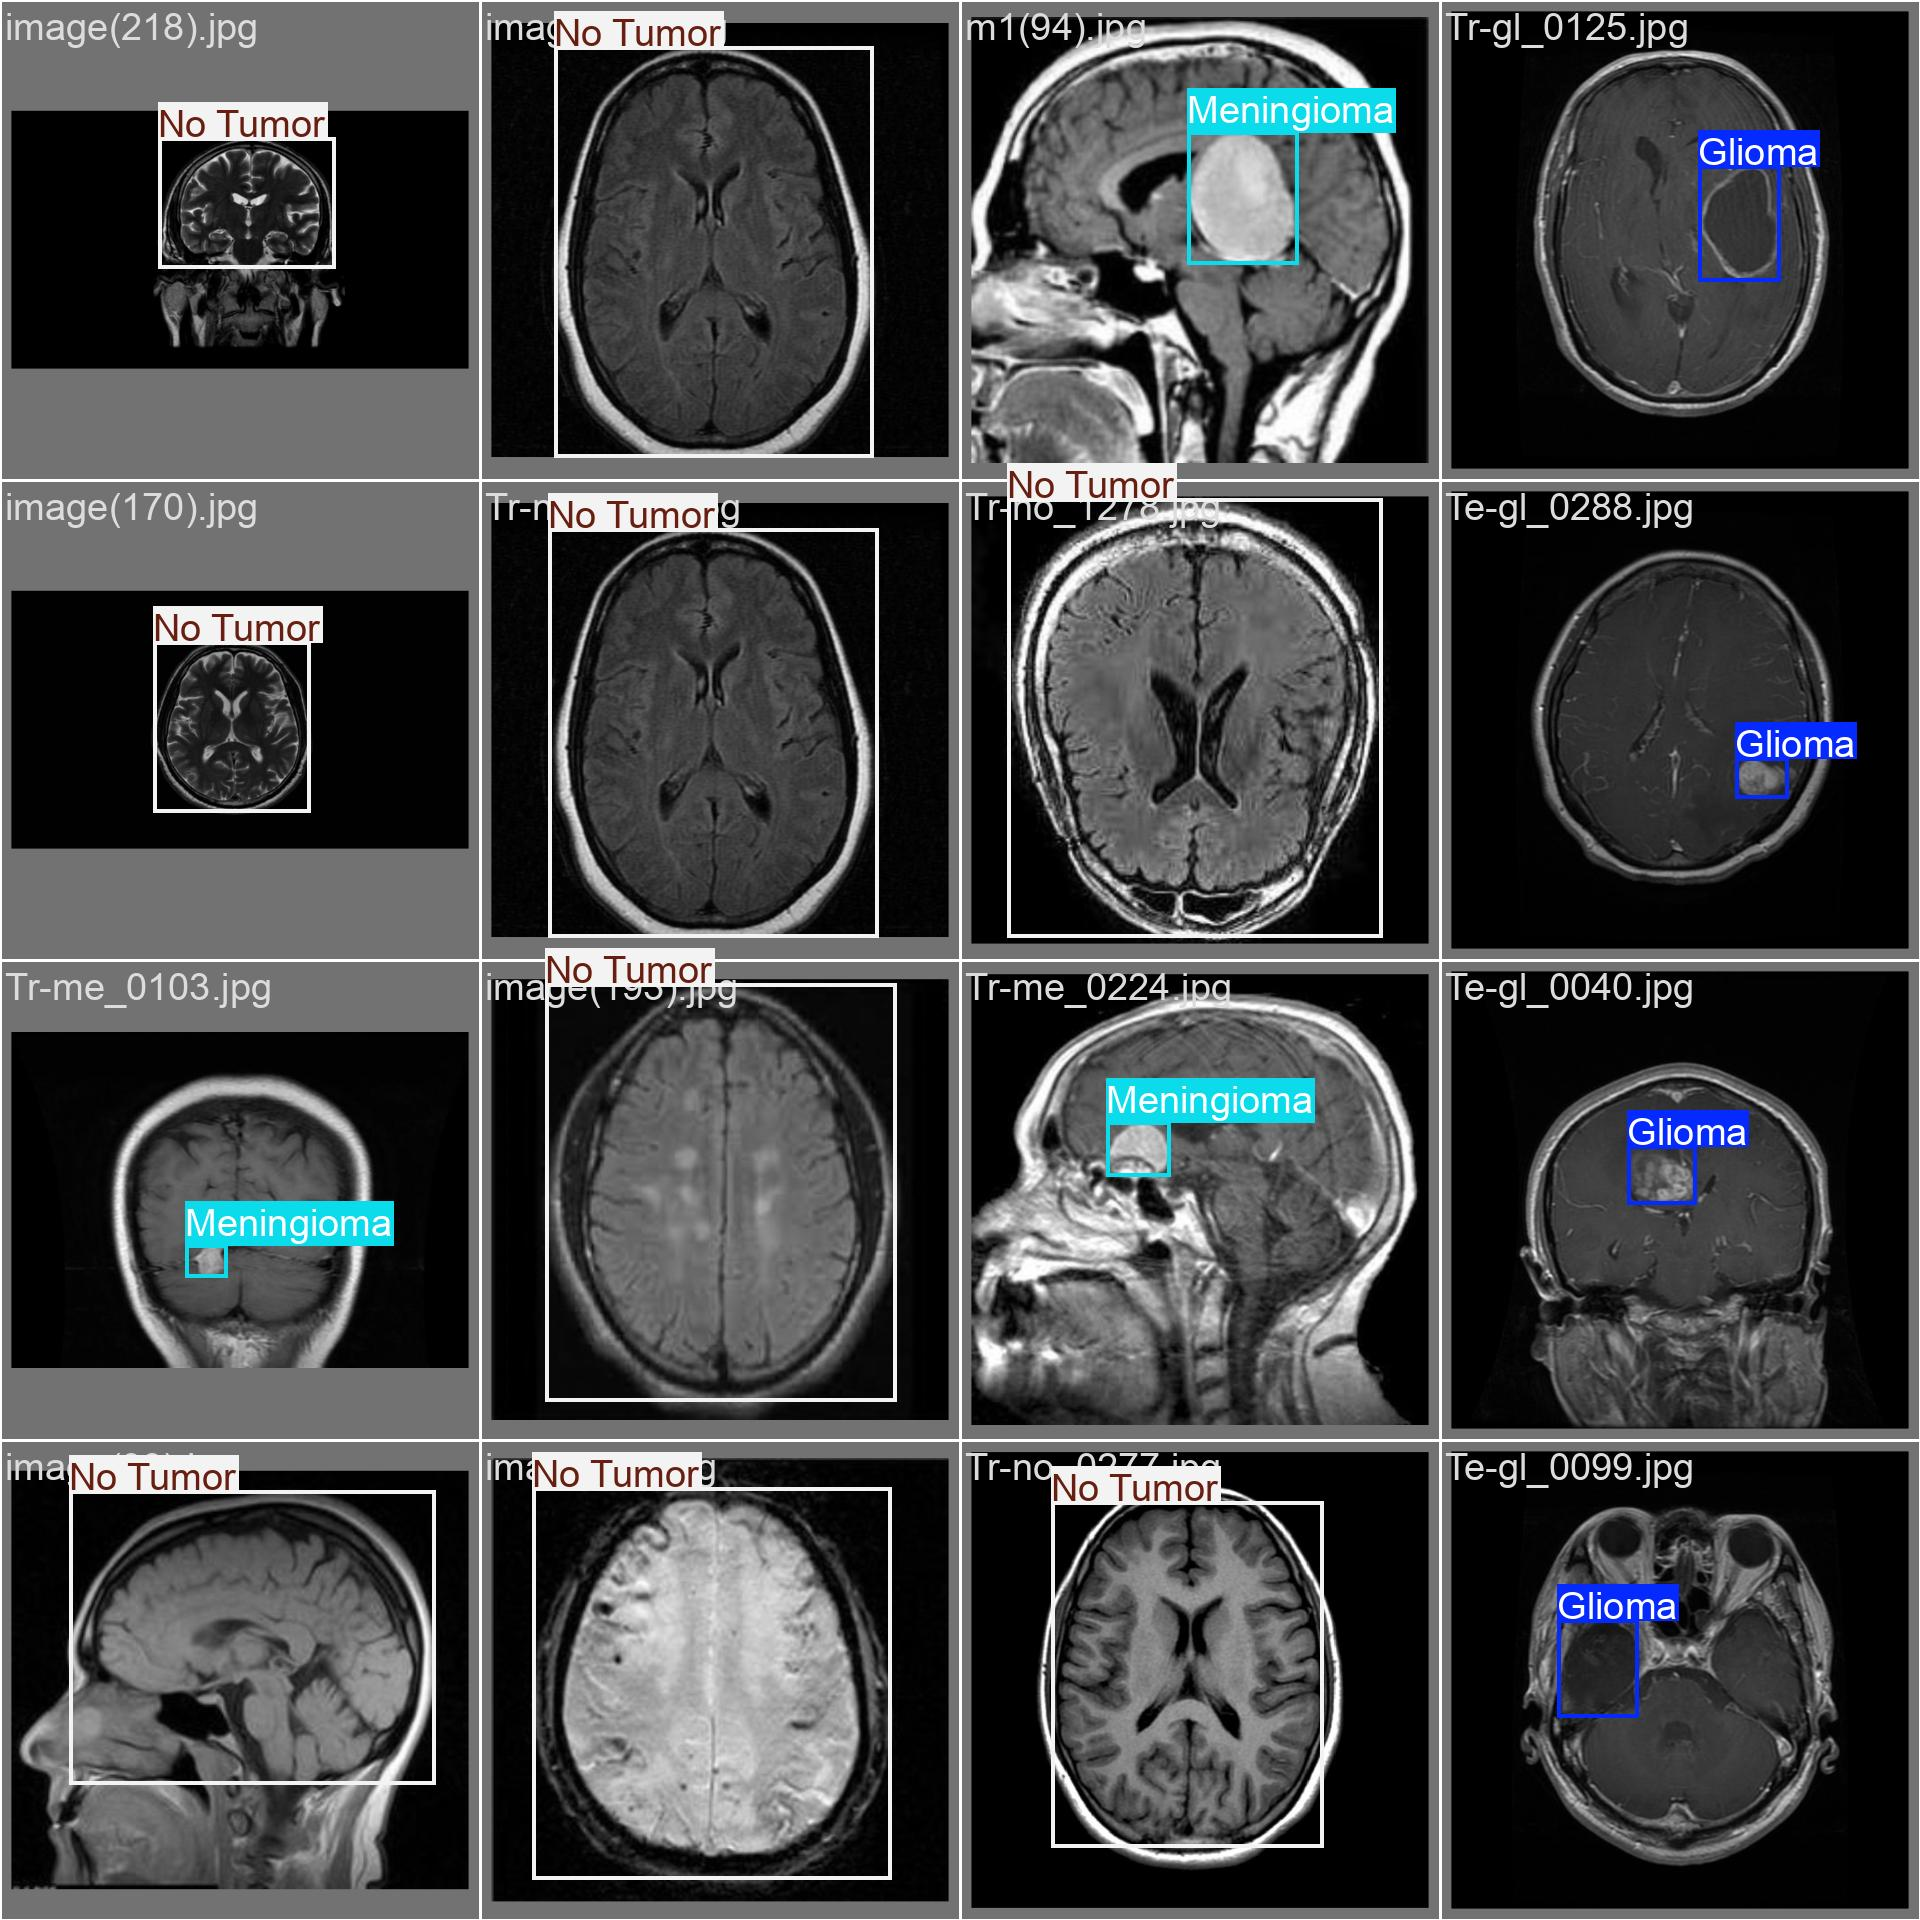

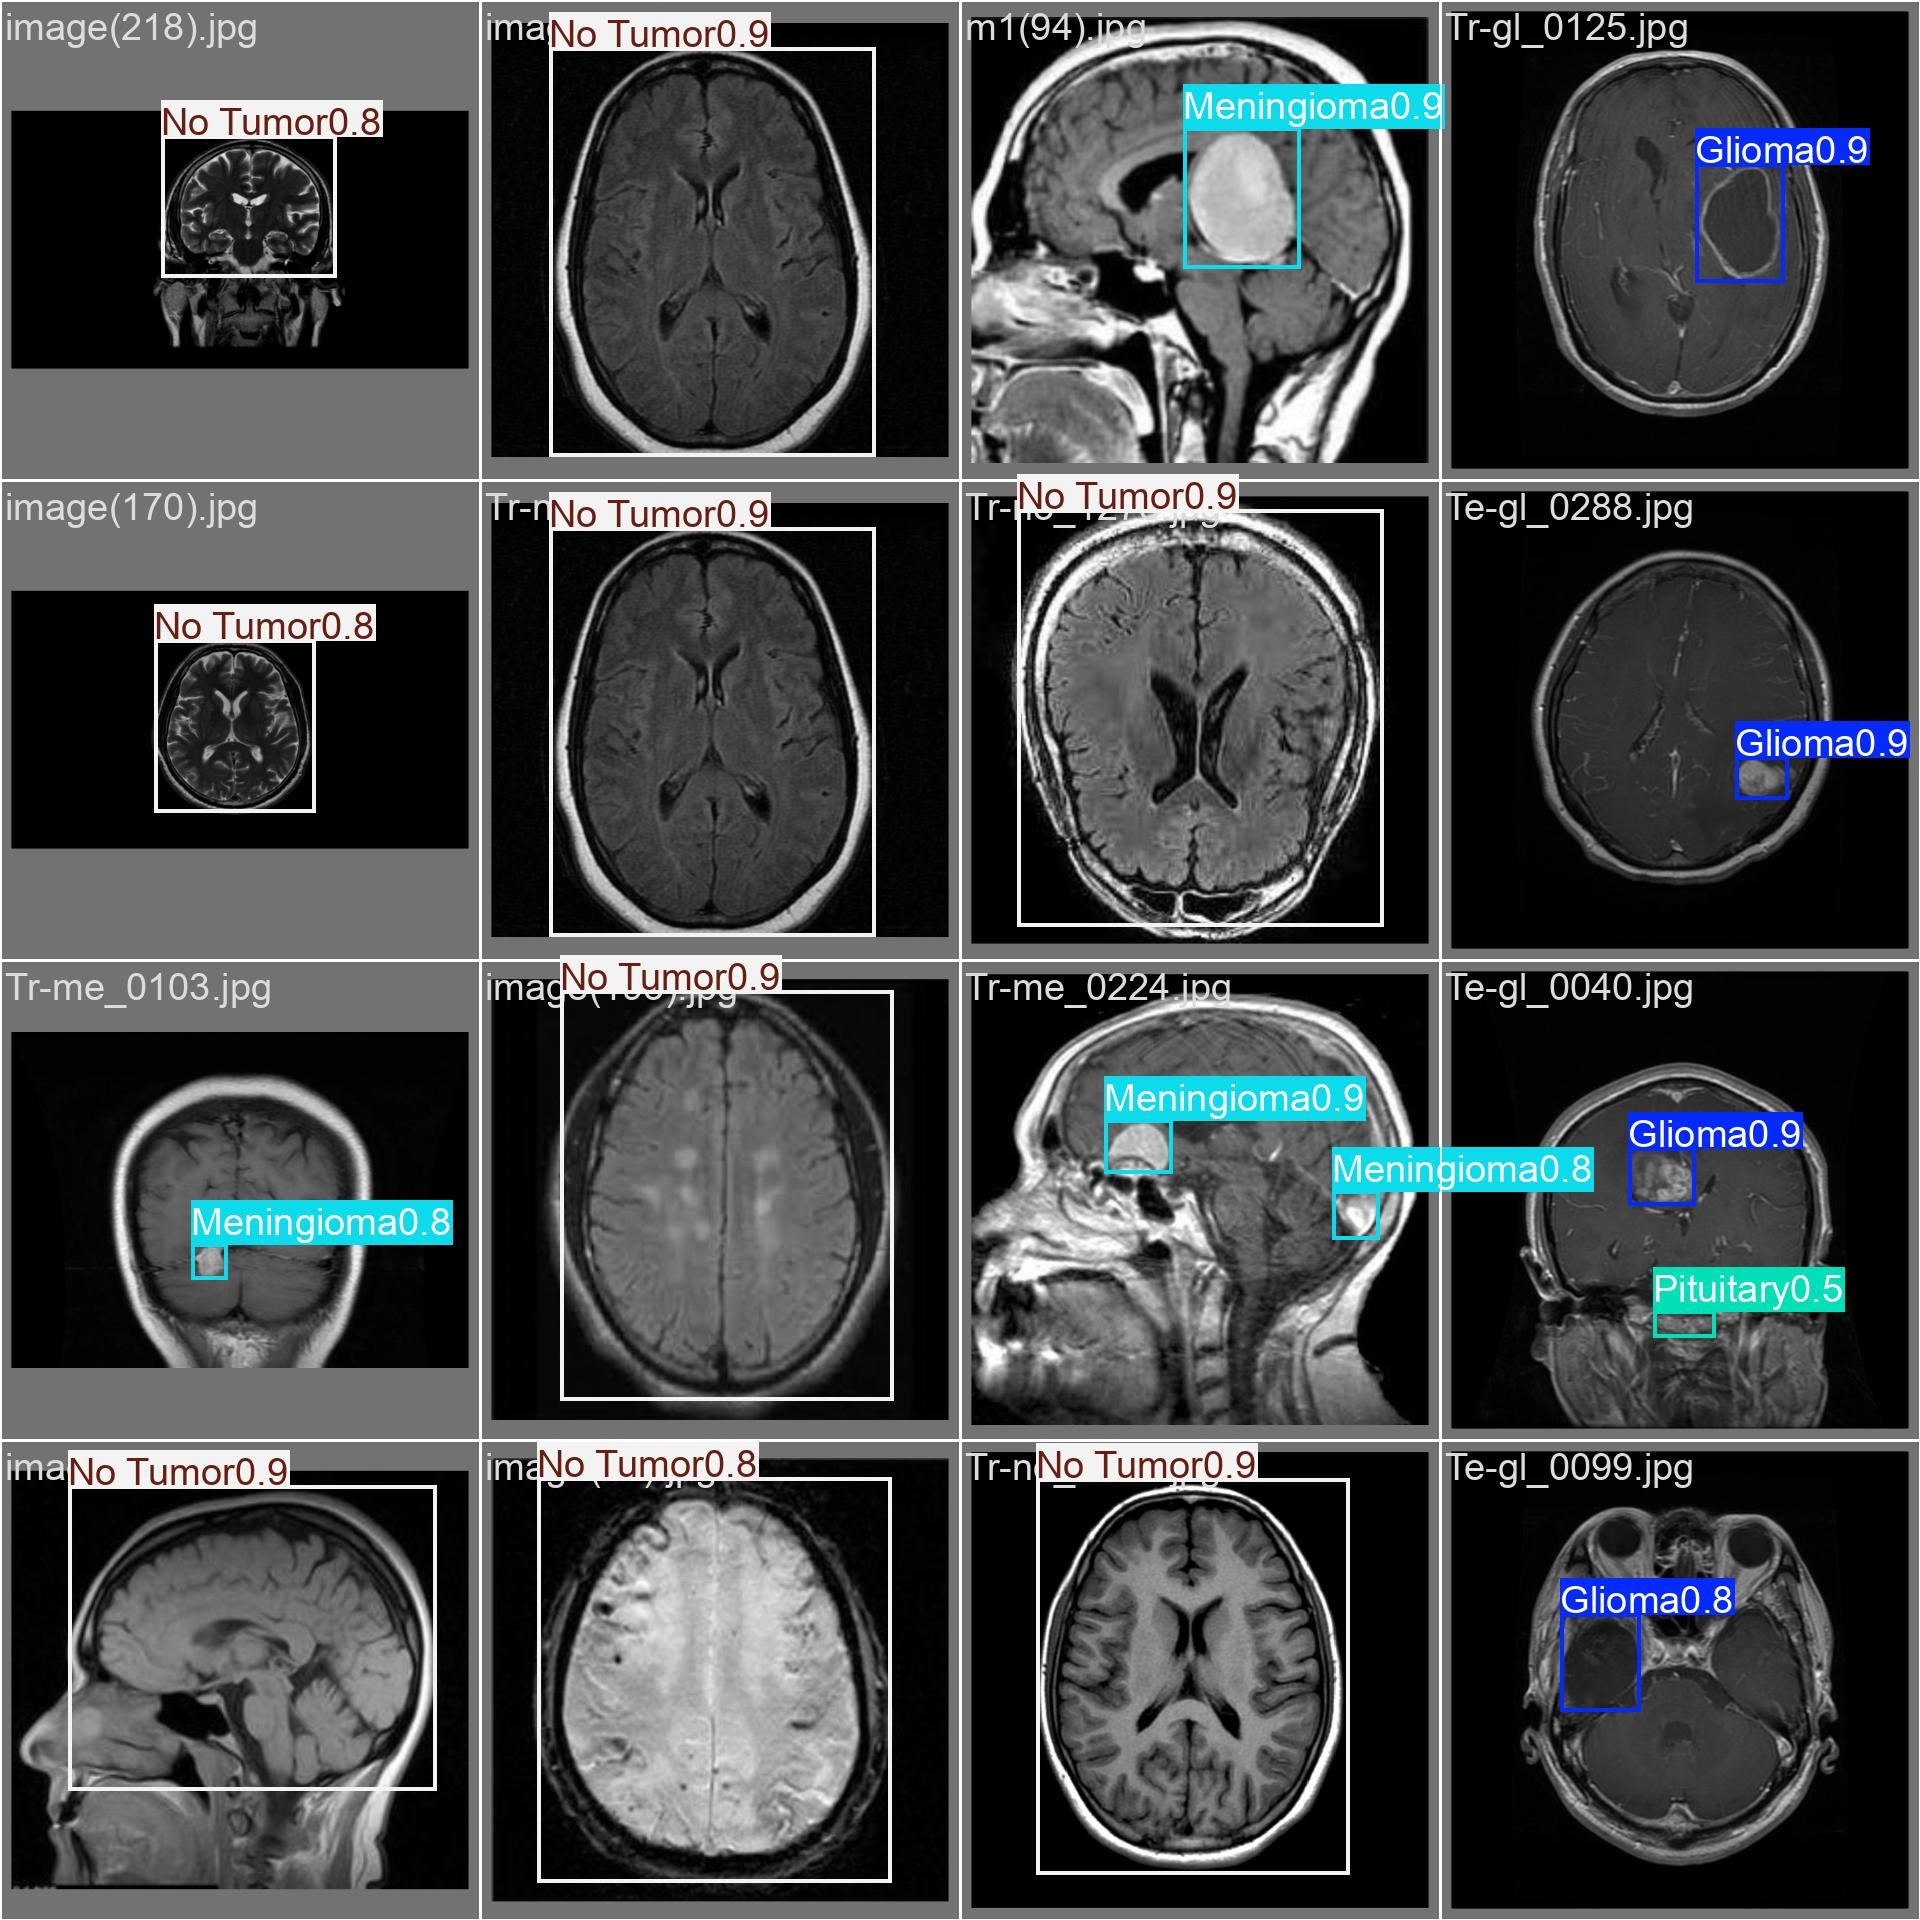

In [44]:
from IPython.display import display, Image

if "TEST_RUN_DIR" not in globals() or TEST_RUN_DIR is None:
    validation_dirs = sorted(
        (path for path in RUNS_DIR.glob("val*") if path.is_dir()),
        key=lambda path: path.stat().st_mtime,
        reverse=True,
    )
    TEST_RUN_DIR = validation_dirs[0] if validation_dirs else None

if TEST_RUN_DIR is None:
    print("No YOLO validation plots were found. Run the evaluation cell first.")
else:
    for filename in ("val_batch0_labels.jpg", "val_batch0_pred.jpg"):
        plot_path = TEST_RUN_DIR / filename
        if plot_path.exists():
            display(Image(filename=str(plot_path)))
        else:
            print("Plot not found:", plot_path)


## 37. Inspect a No Tumor Annotation

Read one No Tumor label file and inspect its normalized bounding-box coordinates. This helps us confirm whether the annotation covers the entire image.

In [45]:
LABEL_DIR = LABELS_DIR / "train"
no_tumor_labels = []

for label_file in LABEL_DIR.glob("*.txt"):
    if any(line.split() and line.split()[0] == "2" for line in label_file.read_text().splitlines()):
        no_tumor_labels.append(label_file)

print("No Tumor label files found:", len(no_tumor_labels))


No Tumor label files found: 676


## 37. Locate No Tumor Label Files

Find the images belonging to the No Tumor class and locate their corresponding YOLO annotation files. We will inspect the annotations before changing anything.

In [46]:
from pathlib import Path

DATASET_DIR = DETECTION_DIR

for split in ["train", "val", "test"]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    print(f"\n{split.upper()}")

    for image_path in sorted(image_dir.iterdir()):
        if "no_tumor" in image_path.name.lower() or "no tumor" in image_path.name.lower():
            label_path = label_dir / f"{image_path.stem}.txt"

            print("Image:", image_path.name)
            print("Label:", label_path.name)
            print("Label exists:", label_path.exists())

            if label_path.exists():
                print("Label contents:", label_path.read_text().strip())

            break


TRAIN

VAL

TEST


## 38. Find No Tumor Bounding Boxes

Search all YOLO label files for annotations whose class ID is 2 (No Tumor). Display a few matching files and their bounding-box coordinates.

In [47]:
from pathlib import Path

DATASET_DIR = DETECTION_DIR

count = 0

for split in ["train", "val", "test"]:
    label_dir = DATASET_DIR / "labels" / split

    for label_path in sorted(label_dir.glob("*.txt")):
        lines = label_path.read_text().strip().splitlines()

        for line in lines:
            values = line.split()

            if values and values[0] == "2":
                print(f"Split: {split}")
                print(f"Label file: {label_path.name}")
                print(f"Annotation: {line}")
                print("-" * 40)

                count += 1
                break

        if count >= 5:
            break

    if count >= 5:
        break

print(f"\nDisplayed {count} label files containing class ID 2.")

Split: train
Label file: 1.txt
Annotation: 2 0.502857 0.675714 0.851429 0.648571
----------------------------------------
Split: train
Label file: 3.txt
Annotation: 2 0.512397 0.513051 0.770248 0.973899
----------------------------------------
Split: train
Label file: 4.txt
Annotation: 2 0.525801 0.507601 0.809609 0.984797
----------------------------------------
Split: train
Label file: 5.txt
Annotation: 2 0.497738 0.451357 0.737557 0.703620
----------------------------------------
Split: train
Label file: 6.txt
Annotation: 2 0.499206 0.515079 0.671429 0.893651
----------------------------------------

Displayed 5 label files containing class ID 2.


## 39. Visualize No Tumor Annotations

Display the images associated with No Tumor annotations and draw their YOLO bounding boxes. Check whether the boxes surround a specific region or almost the entire MRI.

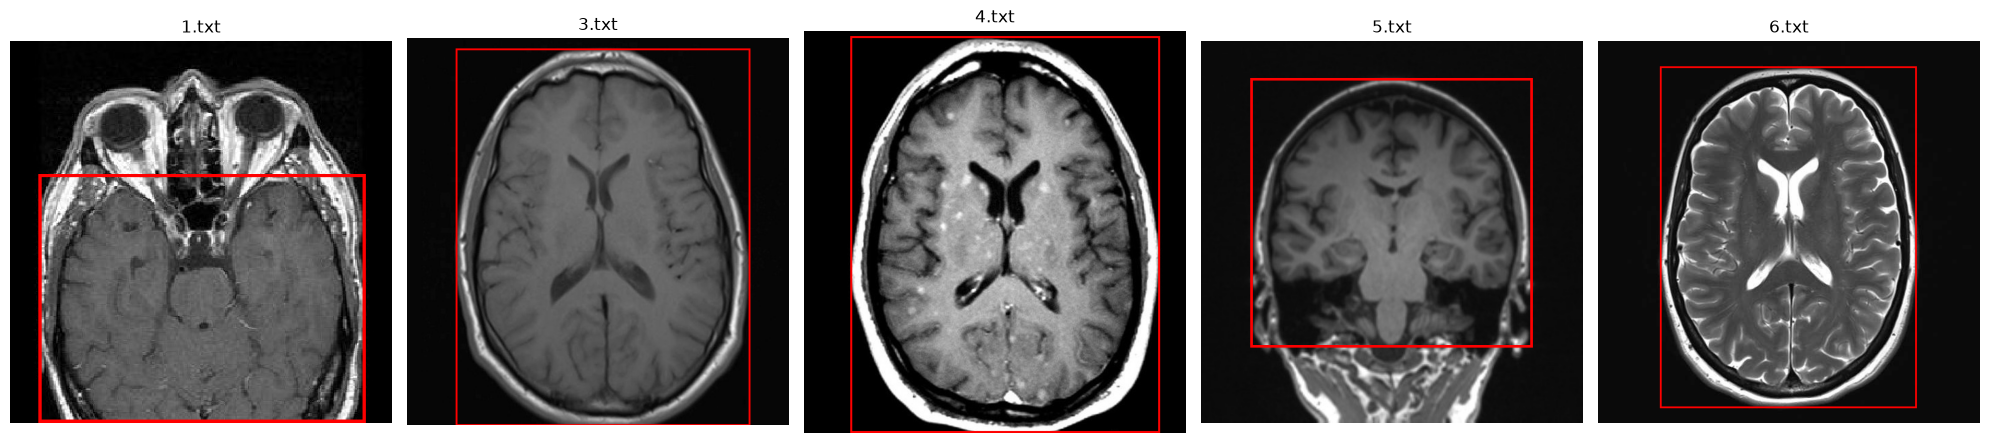

In [48]:
from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

DATASET_DIR = DETECTION_DIR

fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, label_name in zip(axes, ["1.txt", "3.txt", "4.txt", "5.txt", "6.txt"]):
    label_path = DATASET_DIR / "labels" / "train" / label_name
    image_path = DATASET_DIR / "images" / "train" / f"{label_path.stem}.jpg"

    if not image_path.exists():
        ax.set_title(f"Image not found: {label_path.stem}")
        ax.axis("off")
        continue

    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)

    img_w, img_h = image.size

    for line in label_path.read_text().splitlines():
        values = line.split()

        if len(values) != 5:
            continue

        class_id, xc, yc, w, h = map(float, values)

        x1 = (xc - w / 2) * img_w
        y1 = (yc - h / 2) * img_h
        x2 = (xc + w / 2) * img_w
        y2 = (yc + h / 2) * img_h

        draw.rectangle((x1, y1, x2, y2), outline="red", width=3)

    ax.imshow(image)
    ax.set_title(label_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 40. Count Bounding Boxes by Class

Count the annotated objects in the training labels for each class. This helps us understand how the No Tumor class is represented compared with the tumor classes.

In [49]:
from pathlib import Path
from collections import Counter

LABEL_DIR = LABELS_DIR / "train"

class_counts = Counter()

for label_file in LABEL_DIR.glob("*.txt"):
    for line in label_file.read_text().splitlines():
        values = line.split()

        if len(values) == 5:
            class_id = int(values[0])
            class_counts[class_id] += 1

class_names = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary"
}

for class_id, name in class_names.items():
    print(f"{name}: {class_counts[class_id]} bounding boxes")

Glioma: 1281 bounding boxes
Meningioma: 1408 bounding boxes
No Tumor: 676 bounding boxes
Pituitary: 1687 bounding boxes


## 41. Review Detection Dataset Configuration

Inspect the dataset YAML configuration and count how many label files contain No Tumor annotations. Do not modify the dataset.

In [50]:
from pathlib import Path

DATASET_DIR = DETECTION_DIR

yaml_path = DATA_YAML_PATH

print("=== DATASET YAML ===")
print(yaml_path.read_text())

print("\n=== NO TUMOR ANNOTATIONS ===")

for split in ["train", "val", "test"]:
    label_dir = DATASET_DIR / "labels" / split
    matching_files = []

    for label_file in label_dir.glob("*.txt"):
        for line in label_file.read_text().splitlines():
            values = line.split()

            if len(values) == 5 and values[0] == "2":
                matching_files.append(label_file.name)
                break

    print(f"{split}: {len(matching_files)} label files")
    print("Examples:", matching_files[:5])

=== DATASET YAML ===
path: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo
train: images/train
val: images/val
test: images/test
nc: 4
names:
  0: Glioma
  1: Meningioma
  2: No Tumor
  3: Pituitary


=== NO TUMOR ANNOTATIONS ===
train: 676 label files
Examples: ['1.txt', '3.txt', '4.txt', '5.txt', '6.txt']
val: 98 label files
Examples: ['Tr-no_0025.txt', 'Tr-no_0042.txt', 'Tr-no_0048.txt', 'Tr-no_0049.txt', 'Tr-no_0058.txt']
test: 35 label files
Examples: ['image(114).txt', 'image(142).txt', 'image(170).txt', 'image(193).txt', 'image(218).txt']


## 42. Visualize YOLOv8 Predictions on Test Images

Use the trained best model to predict bounding boxes on unseen test images. Save the results so we can inspect the predicted classes, confidence scores, and box locations.

In [51]:
from pathlib import Path
from ultralytics import YOLO

BEST_MODEL_PATH = MODELS_DIR / "best.pt"
if not BEST_MODEL_PATH.exists():
    BEST_MODEL_PATH = RUN_DIR / "weights" / "best.pt"

TEST_IMAGES_DIR = IMAGES_DIR / "test"

model = YOLO(str(BEST_MODEL_PATH))

prediction_results = model.predict(
    source=str(TEST_IMAGES_DIR),
    imgsz=640,
    conf=0.25,
    device=DEVICE,
    save=True,
    project=str(RUNS_DIR),
    name="test_predictions",
)

print("Predictions completed.")
print("Results saved to:")
print(RUNS_DIR / "test_predictions")


image 1/236 /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/test/Te-gl_0040.jpg: 640x640 1 Glioma, 1 Pituitary, 71.0ms
image 2/236 /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/test/Te-gl_0099.jpg: 640x640 1 Glioma, 51.8ms
image 3/236 /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/test/Te-gl_0183.jpg: 640x640 1 Glioma, 51.1ms
image 4/236 /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/test/Te-gl_0249.jpg: 640x640 3 Gliomas, 49.3ms
image 5/236 /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/test/Te-gl_0288.jpg: 640x640 1 Glioma, 43.5ms
image 6/236 /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/test/Te-pi_0038.jpg: 640x640 1 Pituitary, 70.8ms
image 7/236 /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/detection_yolo/images/test/Tr-gl_0044.jpg: 640x640 1 Glioma, 74.5ms
image 8/236 /home/lahcen404/YouCode-Y2/BrainScanAI-V2/datasets/de

## 43. Visualize Test Predictions

Display a few images with the bounding boxes predicted by the trained YOLOv8 model. Inspect the class labels, confidence scores, and box locations.

Number of saved prediction images: 236
Tr-no_0593.jpg


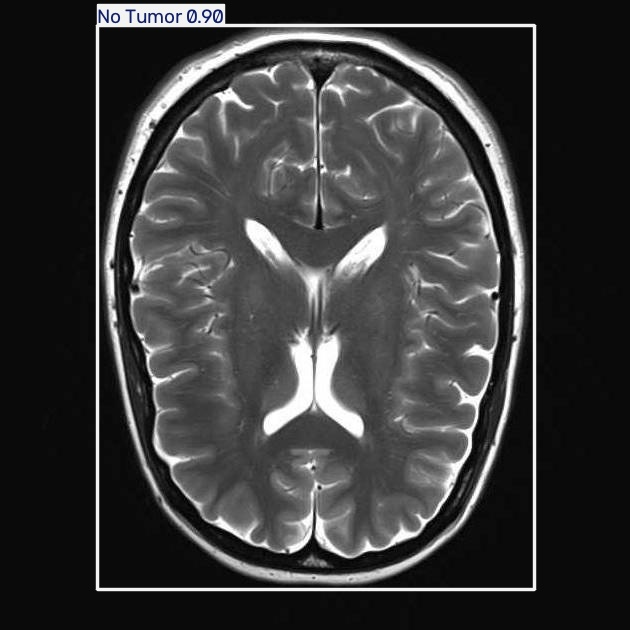

Tr-me_0651.jpg


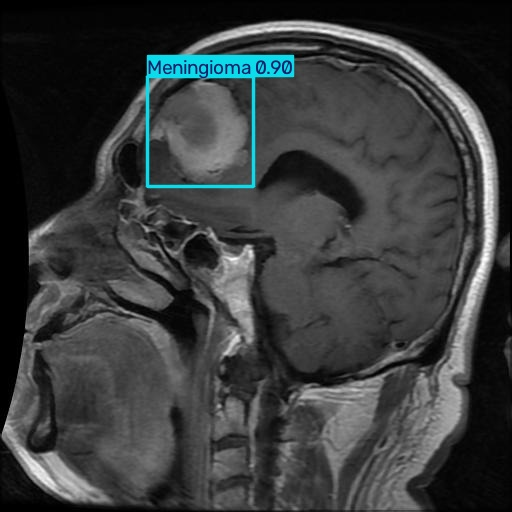

Tr-no_0218.jpg


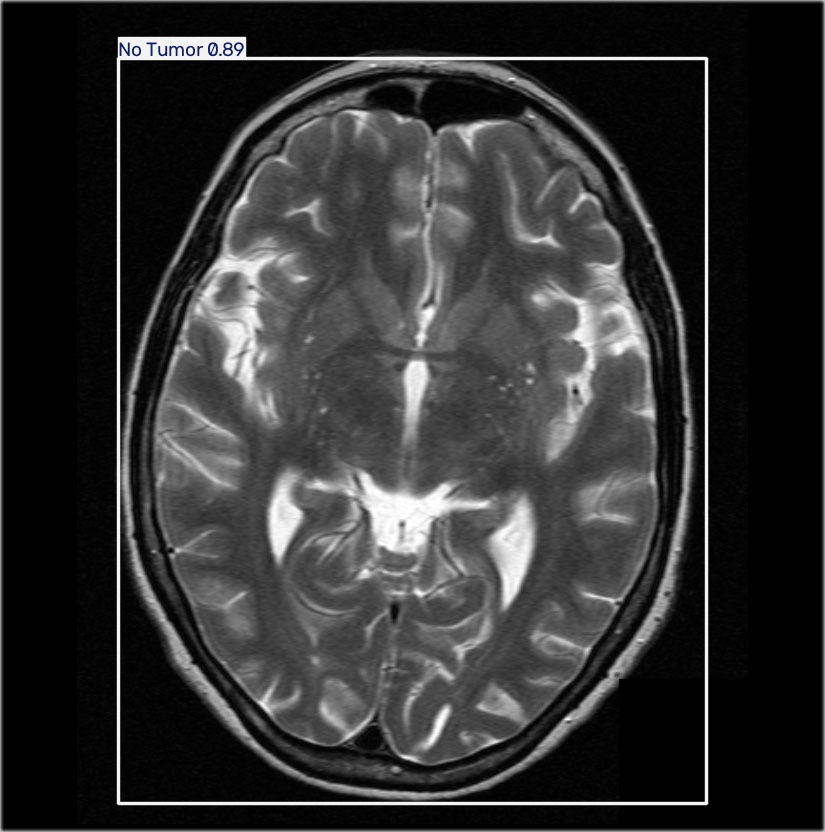

Tr-pi_0576.jpg


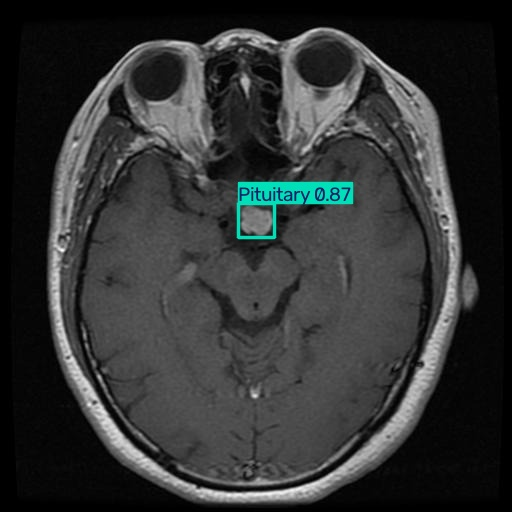

p (720).jpg


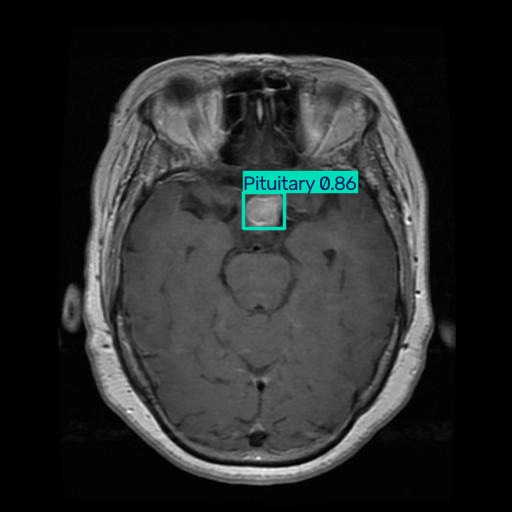

In [52]:
from pathlib import Path
from IPython.display import display, Image
import random

PREDICTIONS_DIR = RUNS_DIR / "test_predictions"

prediction_images = sorted(
    list(PREDICTIONS_DIR.glob("*.jpg")) +
    list(PREDICTIONS_DIR.glob("*.png")) +
    list(PREDICTIONS_DIR.glob("*.jpeg"))
)

print("Number of saved prediction images:", len(prediction_images))

for image_path in random.sample(
    prediction_images,
    min(5, len(prediction_images))
):
    print(image_path.name)
    display(Image(filename=str(image_path)))

## 44. Compare One Test Prediction with Its Ground Truth

Display the predicted image and the original annotated image for the same test sample. Compare the predicted class and bounding-box location with the ground-truth annotation.

YOLOv8 prediction:


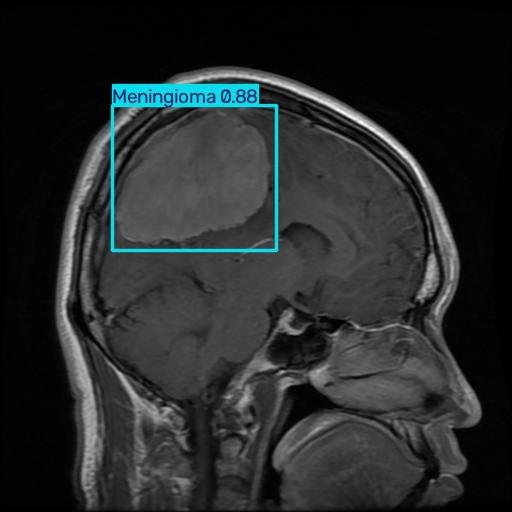

Ground-truth batch visualizations are stored in:
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/runs/detect/val


In [53]:
from pathlib import Path
from IPython.display import display, Image

DATASET_DIR = DETECTION_DIR
PREDICTIONS_DIR = RUNS_DIR / "test_predictions"
EVALUATION_DIR = RUNS_DIR / "val"

image_name = "Tr-me_1177.jpg"

print("YOLOv8 prediction:")
display(Image(filename=str(PREDICTIONS_DIR / image_name)))

print("Ground-truth batch visualizations are stored in:")
print(EVALUATION_DIR)

## 45. Compare Prediction with Ground Truth

- **Prediction:** The bounding box and class predicted by YOLOv8.
- **Ground truth:** The bounding box and class provided by our dataset.

Displaying both images helps us check whether the model detects the correct region.

LEFT: Ground truth (green boxes)


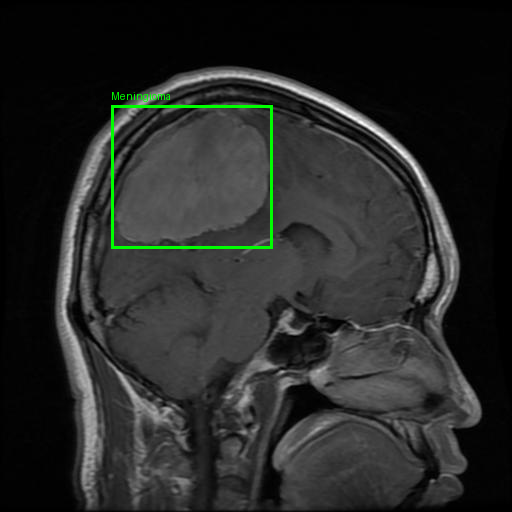

RIGHT: YOLOv8 prediction


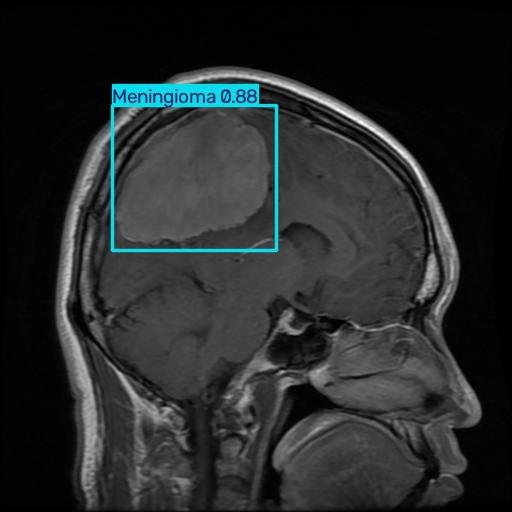

In [54]:
from pathlib import Path
from PIL import Image, ImageDraw
from IPython.display import display

DATASET_DIR = DETECTION_DIR
PREDICTIONS_DIR = RUNS_DIR / "test_predictions"

image_name = "Tr-me_1177.jpg"

# Locate the original image and its annotation
original_path = DATASET_DIR / "images" / "test" / image_name
label_path = DATASET_DIR / "labels" / "test" / f"{Path(image_name).stem}.txt"

class_names = {
    0: "Glioma",
    1: "Meningioma",
    2: "No Tumor",
    3: "Pituitary",
}

# Load the original image
original_image = Image.open(original_path).convert("RGB")
draw = ImageDraw.Draw(original_image)

# Read ground-truth boxes and convert normalized YOLO coordinates to pixels
image_width, image_height = original_image.size

if label_path.exists():
    for line in label_path.read_text().splitlines():
        values = line.split()

        if len(values) != 5:
            continue

        class_id, x_center, y_center, box_width, box_height = map(float, values)

        x_center *= image_width
        y_center *= image_height
        box_width *= image_width
        box_height *= image_height

        x1 = x_center - box_width / 2
        y1 = y_center - box_height / 2
        x2 = x_center + box_width / 2
        y2 = y_center + box_height / 2

        class_name = class_names[int(class_id)]

        draw.rectangle((x1, y1, x2, y2), outline="lime", width=3)
        draw.text((x1, max(0, y1 - 15)), class_name, fill="lime")
else:
    print("No ground-truth label file found:", label_path)

print("LEFT: Ground truth (green boxes)")
display(original_image)

print("RIGHT: YOLOv8 prediction")
display(Image.open(PREDICTIONS_DIR / image_name))


### Save Final YOLOv8 Test Metrics

Save the model's test evaluation metrics to a CSV file.

This file will help us document the model's performance and reuse the results in the BrainScanAI-V2 project report.


In [55]:
import pandas as pd

if "test_results" not in globals():
    raise RuntimeError("Run the YOLO test evaluation cell before calculating metrics.")

results_dict = test_results.results_dict

def metric_value(name):
    if name not in results_dict:
        raise KeyError(f"YOLO evaluation did not provide the expected metric: {name}")
    return float(results_dict[name])


def count_yolo_test_data():
    image_dir = IMAGES_DIR / "test"
    label_dir = LABELS_DIR / "test"
    image_suffixes = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
    image_paths = [path for path in image_dir.iterdir() if path.is_file() and path.suffix.lower() in image_suffixes]
    label_paths = [path for path in label_dir.glob("*.txt") if path.is_file()]
    instances = 0
    for label_path in label_paths:
        instances += sum(1 for line in label_path.read_text(encoding="utf-8").splitlines() if line.strip())
    return len(image_paths), instances


test_images, test_instances = count_yolo_test_data()
metrics = {
    "Model": BEST_MODEL_PATH.name,
    "Dataset": "Test",
    "Images": test_images,
    "Instances": test_instances,
    "Precision": metric_value("metrics/precision(B)"),
    "Recall": metric_value("metrics/recall(B)"),
    "mAP50": metric_value("metrics/mAP50(B)"),
    "mAP50-95": metric_value("metrics/mAP50-95(B)"),
}

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
metrics_df = pd.DataFrame([metrics])
metrics_path = RESULTS_DIR / "yolov8_test_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

print("Metrics saved successfully!")
print(f"File: {metrics_path}")
display(metrics_df)


Metrics saved successfully!
File: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/results/yolov8_test_metrics.csv


,Model,Dataset,Images,Instances,Precision,Recall,mAP50,mAP50-95
0,best.pt,Test,236,265,0.925972,0.926905,0.954726,0.718611


### Locate the Best YOLOv8 Checkpoint

The local checkpoint is stored under `models/detection/best.pt` after training or artifact import.


In [56]:

from pathlib import Path

print("Searching for best.pt...")

matches = list(PROJECT_ROOT.rglob("best.pt"))

if matches:
    print(f"\nFound {len(matches)} file(s):")
    for path in matches:
        print(path)
else:
    print("No best.pt found inside the project.")


Searching for best.pt...

Found 1 file(s):
/home/lahcen404/YouCode-Y2/BrainScanAI-V2/models/detection/best.pt



### Prepare the Best YOLOv8 Model

YOLOv8 saves the best checkpoint during training as `best.pt`.

We will copy this checkpoint into the project's `models` directory so that the application can load it from a predictable location.

We keep the original checkpoint unchanged.


In [57]:

from pathlib import Path
import shutil

# Prefer an existing project checkpoint, then check the training run.
source_candidates = [
    MODELS_DIR / "best.pt",
    RUN_DIR / "weights" / "best.pt",
]
BEST_MODEL_PATH = next(
    (path for path in source_candidates if path.is_file()),
    None,
        )

# Create the destination folder
MODELS_DIR = PROJECT_ROOT / "models" / "detection"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

if BEST_MODEL_PATH is None:
    raise FileNotFoundError(
        "No YOLO checkpoint found. Train the model first or copy best.pt "
        f"to {MODELS_DIR}. Checked: {source_candidates}"
    )

DESTINATION_PATH = MODELS_DIR / "best.pt"
if BEST_MODEL_PATH != DESTINATION_PATH:
    shutil.copy2(BEST_MODEL_PATH, DESTINATION_PATH)
else:
    print("Checkpoint already exists at the destination.")

print("Model copied successfully!")
print(f"Destination: {DESTINATION_PATH}")
print(f"Size: {DESTINATION_PATH.stat().st_size / (1024**2):.2f} MB")


Checkpoint already exists at the destination.
Model copied successfully!
Destination: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/models/detection/best.pt
Size: 6.20 MB



### Package YOLOv8 Artifacts

Create a ZIP archive containing the trained model and its test metrics.

This makes it easier to download the artifacts from Google Colab and transfer them into the local BrainScanAI-V2 repository.


In [58]:

from pathlib import Path
import zipfile

PROJECT_DIR = PROJECT_ROOT
ZIP_PATH = PROJECT_DIR / "yolov8_artifacts.zip"

files_to_package = [
    PROJECT_DIR / "models" / "detection" / "best.pt",
    PROJECT_DIR / "results" / "yolov8_test_metrics.csv",
]

# Check that both files exist
for file_path in files_to_package:
    if not file_path.exists():
        raise FileNotFoundError(f"Missing file: {file_path}")

# Create the ZIP archive
with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for file_path in files_to_package:
        zip_file.write(
            file_path,
            arcname=str(file_path.relative_to(PROJECT_DIR))
        )

print("ZIP created successfully!")
print(f"Path: {ZIP_PATH}")
print(f"Size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
print("\nFiles included:")
with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:
    for name in zip_file.namelist():
        print("-", name)


ZIP created successfully!
Path: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/yolov8_artifacts.zip
Size: 5.63 MB

Files included:
- models/detection/best.pt
- results/yolov8_test_metrics.csv



### Download YOLOv8 Artifacts

Download the ZIP archive from Google Colab to your computer.

The archive contains:
- `models/best.pt`
- `results/yolov8_test_metrics.csv`


In [59]:
print("Artifact archive creation is not needed in VS Code.")
print("Best model:", MODELS_DIR / "best.pt")
print("Metrics:", RESULTS_DIR / "yolov8_test_metrics.csv")


Artifact archive creation is not needed in VS Code.
Best model: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/models/detection/best.pt
Metrics: /home/lahcen404/YouCode-Y2/BrainScanAI-V2/results/yolov8_test_metrics.csv
